In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Date and time handling
from datetime import datetime

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Visualisation settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Sri_Lanka_Tea_Areas_Daily_Weather_2015-2026.xlsx to Sri_Lanka_Tea_Areas_Daily_Weather_2015-2026.xlsx
Saving ALL FACTORIES 2023-2026 (1).xlsx to ALL FACTORIES 2023-2026 (1).xlsx
Saving Manual_Entry.xlsx to Manual_Entry.xlsx
Saving Sri Lanka tea production by elevation and region.xlsx to Sri Lanka tea production by elevation and region.xlsx
Saving Sri Lanka monthly tea production by process type.xlsx to Sri Lanka monthly tea production by process type.xlsx


In [ ]:
import os

print(os.listdir('/content'))

['.config', 'Sri_Lanka_Tea_Areas_Daily_Weather_2015-2026.xlsx', 'Sri Lanka monthly tea production by process type.xlsx', 'Sri Lanka tea production by elevation and region.xlsx', 'ALL FACTORIES 2023-2026 (1).xlsx', 'Manual_Entry.xlsx', 'sample_data']


In [ ]:
factory_file = '/content/ALL FACTORIES 2023-2026.xlsx'

elevation_file = '/content/Sri Lanka tea production by elevation and region.xlsx'

process_file = '/content/Sri Lanka monthly tea production by process type.xlsx'

manual_file = '/content/Manual_Entry.xlsx'

In [ ]:
# Update file paths to match the uploaded filenames with (1) suffix if the originals are missing, or use correct ones
import os

# Helper function to find the best matching file path
def get_existing_path(default_path):
    if os.path.exists(default_path):
        return default_path
    # Fallback to the one with " (1)" suffix if it exists
    suffix_path = default_path.replace('.xlsx', ' (1).xlsx')
    if os.path.exists(suffix_path):
        return suffix_path
    return default_path

factory_file_path = get_existing_path('/content/ALL FACTORIES 2023-2026.xlsx')
elevation_file_path = get_existing_path('/content/Sri Lanka tea production by elevation and region.xlsx')
process_file_path = get_existing_path('/content/Sri Lanka monthly tea production by process type.xlsx')
manual_file_path = get_existing_path('/content/Manual_Entry.xlsx')

# Factory data
factory_raw = pd.read_excel(
    factory_file_path,
    sheet_name='3 YEAR GREEN LEAF QTY ACU GROUP',
    header=None
)

# Elevation data
elevation_df = pd.read_excel(
    elevation_file_path,
    sheet_name='Elevation_Monthly'
)

district_df = pd.read_excel(
    elevation_file_path,
    sheet_name='District_Monthly'
)

group_df = pd.read_excel(
    elevation_file_path,
    sheet_name='Group_Monthly'
)

# Process type data
process_df = pd.read_excel(
    process_file_path,
    sheet_name='Monthly_Process'
)

# Manual entry data
manual_raw = pd.read_excel(
    manual_file_path,
    sheet_name='Sheet1',
    header=None
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


##Data Set Inspection and understanding

In [ ]:
datasets = {
    "Factory": factory_raw,
    "Elevation": elevation_df,
    "District": district_df,
    "Regional Groups": group_df,
    "Process Type": process_df,
    "Manual Entry": manual_raw
}

for name, df in datasets.items():

    print("\n" + "="*60)
    print("DATASET:", name)
    print("="*60)

    print("Shape:", df.shape)

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)


DATASET: Factory
Shape: (45, 7)

First 5 rows:


,0,1,2,3,4,5,6
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,3-Year Green Leaf Quantity Of ACU Group,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,YEAY,MONTH,ACU,T VALLEY,T VIEW,NEW PANAWENNA,NEW NAWALAKANDA
4,2023,SEP,172081,111713,175878,0,0



Column names:
[0, 1, 2, 3, 4, 5, 6]

Data types:
0    object
1    object
2    object
3    object
4    object
5    object
6    object
dtype: object

DATASET: Elevation
Shape: (132, 12)

First 5 rows:


,month_start,year,month,High grown (t),Medium grown (t),Low grown (t),Total as published (t),High + Medium + Low (t),Difference (t),High share,Medium share,Low share
0,2015-01-01,2015,1,4853.33985,3194.71825,15252.07693,23300.13503,23300.13503,0,0.208297,0.137112,0.654592
1,2015-02-01,2015,2,6293.41193,4398.98250,14920.54556,25612.93999,25612.93999,0,0.245712,0.171748,0.582539
2,2015-03-01,2015,3,6938.41367,4788.30475,18710.44339,30437.16181,30437.16181,0,0.227959,0.157318,0.614724
3,2015-04-01,2015,4,8300.50240,5685.61500,17641.07050,31627.18790,31627.18790,0,0.262448,0.179770,0.557782
4,2015-05-01,2015,5,8216.22218,5339.89900,18875.63967,32431.76085,32431.76085,0,0.253339,0.164650,0.582011



Column names:
['month_start', 'year', 'month', 'High grown (t)', 'Medium grown (t)', 'Low grown (t)', 'Total as published (t)', 'High + Medium + Low (t)', 'Difference (t)', 'High share', 'Medium share', 'Low share']

Data types:
month_start                datetime64[ns]
year                                int64
month                               int64
High grown (t)                    float64
Medium grown (t)                  float64
Low grown (t)                     float64
Total as published (t)            float64
High + Medium + Low (t)           float64
Difference (t)                      int64
High share                        float64
Medium share                      float64
Low share                         float64
dtype: object

DATASET: District
Shape: (5016, 7)

First 5 rows:


,month_start,year,month,district,regional group,production (kg),production (t)
0,2015-01-01,2015,1,Nuwara Eliya,Nuwara Eliya,240949.5,240.9495
1,2015-01-01,2015,1,Agarapathana,Westerns,723975.0,723.9750
2,2015-01-01,2015,1,Bogawantalawa,Westerns,458924.0,458.9240
3,2015-01-01,2015,1,Hatton/Dickoya,Westerns,603749.0,603.7490
4,2015-01-01,2015,1,Nanuoya/Lindula/Talawakele,Westerns,681714.5,681.7145


... (3 outputs left out)

,month_start,year,Orthodox (kg),CTC (kg),Green Tea (kg),Total as published (kg),Sum of types (kg),Orthodox share,CTC share,Green share,Total in Tea Board elevation file (kg),Site minus elevation file (%),Data-quality note
0,2015-01-01,2015,21456754.0,1596462.0,246920.0,23300135.0,23300136.0,0.920885,0.068517,0.010597,23300135.0,0.0,NaN
1,2015-02-01,2015,23826957.0,1503753.0,282230.0,25612940.0,25612940.0,0.930270,0.058711,0.011019,25612940.0,0.0,NaN
2,2015-03-01,2015,28403018.0,1726289.0,307855.0,30437162.0,30437162.0,0.933169,0.056716,0.010114,30437162.0,0.0,NaN
3,2015-04-01,2015,29634742.0,1726795.0,265651.0,31627188.0,31627188.0,0.937002,0.054598,0.008399,31627188.0,0.0,NaN
4,2015-05-01,2015,30441493.0,1771119.0,219149.0,32431761.0,32431761.0,0.938632,0.054611,0.006757,32431761.0,0.0,NaN



Column names:
['month_start', 'year', 'Orthodox (kg)', 'CTC (kg)', 'Green Tea (kg)', 'Total as published (kg)', 'Sum of types (kg)', 'Orthodox share', 'CTC share', 'Green share', 'Total in Tea Board elevation file (kg)', 'Site minus elevation file (%)', 'Data-quality note']

Data types:
month_start                               datetime64[ns]
year                                               int64
Orthodox (kg)                                    float64
CTC (kg)                                         float64
Green Tea (kg)                                   float64
Total as published (kg)                          float64
Sum of types (kg)                                float64
Orthodox share                                   float64
CTC share                                        float64
Green share                                      float64
Total in Tea Board elevation file (kg)           float64
Site minus elevation file (%)                    float64
Data-quality note          

,0,1,2,3,4
0,NaN,Tea Produced (Kg) each year,NaN,NaN,NaN
1,Date,2023,2024.0,2025.0,2026.0
2,2026-01-01 00:00:00,1076,687.0,1513.0,2750.0
3,2026-01-02 00:00:00,2400,2466.0,2748.0,2453.0
4,2026-01-03 00:00:00,4833,4005.0,4552.0,344.0



Column names:
[0, 1, 2, 3, 4]

Data types:
0     object
1     object
2    float64
3    float64
4    float64
dtype: object


##Preprocessing the primary data set

In [ ]:
elevation_clean = elevation_df.copy()
district_clean = district_df.copy()
group_clean = group_df.copy()

In [ ]:
elevation_clean['month_start'] = pd.to_datetime(
    elevation_clean['month_start']
)

district_clean['month_start'] = pd.to_datetime(
    district_clean['month_start']
)

group_clean['month_start'] = pd.to_datetime(
    group_clean['month_start']
)

In [ ]:
for df in [elevation_clean, district_clean]:

    df['year'] = df['year'].astype(int)
    df['month'] = df['month'].astype(int)

In [ ]:
print("Elevation missing values:")
display(elevation_clean.isnull().sum())

print("District missing values:")
display(district_clean.isnull().sum())

print("Regional group missing values:")
display(group_clean.isnull().sum())

def missing_report(df):

    report = pd.DataFrame({
        'Missing Count': df.isnull().sum(),
        'Missing Percentage':
            (df.isnull().sum() / len(df)) * 100
    })

    return report.sort_values(
        'Missing Percentage',
        ascending=False
    )

display(missing_report(district_clean))

Elevation missing values:


,0
month_start,0
year,0
month,0
High grown (t),0
Medium grown (t),0
Low grown (t),0
Total as published (t),0
High + Medium + Low (t),0
Difference (t),0
High share,0


District missing values:


,0
month_start,0
year,0
month,0
district,0
regional group,0
production (kg),0
production (t),0


Regional group missing values:


,0
month_start,0
Nuwara Eliya,0
Westerns,0
Mediums,0
Uda Pussellawa,0
Uvas,0
Low Grown,0
Total (t),0


,Missing Count,Missing Percentage
month_start,0,0.0
year,0,0.0
month,0,0.0
district,0,0.0
regional group,0,0.0
production (kg),0,0.0
production (t),0,0.0


In [ ]:
print("Elevation duplicates:",
      elevation_clean.duplicated().sum())

print("District duplicates:",
      district_clean.duplicated().sum())

print("Group duplicates:",
      group_clean.duplicated().sum())

Elevation duplicates: 0
District duplicates: 0
Group duplicates: 0


In [ ]:
district_clean[
    district_clean.duplicated(
        subset=['month_start', 'district'],
        keep=False
    )
]

,month_start,year,month,district,regional group,production (kg),production (t)


In [ ]:
production_columns = [
    'production (kg)',
    'production (t)'
]

display(district_clean[production_columns].describe())

,production (kg),production (t)
count,5.016000e+03,5016.000000
mean,6.273339e+05,627.333888
std,8.363112e+05,836.311158
min,9.831000e+03,9.831000
25%,2.013192e+05,201.319225
50%,3.694618e+05,369.461750
75%,6.266092e+05,626.609163
max,5.471138e+06,5471.138000


In [ ]:
district_clean[
    (district_clean['production (kg)'] < 0) |
    (district_clean['production (t)'] < 0)
]

,month_start,year,month,district,regional group,production (kg),production (t)


In [ ]:
district_clean['unit_difference'] = (
    district_clean['production (kg)'] / 1000
    - district_clean['production (t)']
)

print(
    district_clean['unit_difference'].abs().max()
)

0.0


In [ ]:
print(
    "Start date:",
    district_clean['month_start'].min()
)

print(
    "End date:",
    district_clean['month_start'].max()
)

print(
    "Number of months:",
    district_clean['month_start'].nunique()
)

print(
    "Number of districts:",
    district_clean['district'].nunique()
)

Start date: 2015-01-01 00:00:00
End date: 2025-12-01 00:00:00
Number of months: 132
Number of districts: 38


In [ ]:
district_clean['2017_discrepancy_period'] = (
    (district_clean['year'] == 2017) &
    (district_clean['month'].isin([1, 2, 5, 6, 11]))
)

## 03 – Preprocessing: Process Type Data

In [ ]:
process_clean = process_df.copy()

In [ ]:
process_clean['month_start'] = pd.to_datetime(
    process_clean['month_start']
)

In [ ]:
print(process_clean.isnull().sum())

month_start                                 0
year                                        0
Orthodox (kg)                               1
CTC (kg)                                    1
Green Tea (kg)                              1
Total as published (kg)                     1
Sum of types (kg)                           1
Orthodox share                              1
CTC share                                   1
Green share                                 1
Total in Tea Board elevation file (kg)      9
Site minus elevation file (%)              10
Data-quality note                         129
dtype: int64


In [ ]:
missing_process = process_clean[
    process_clean[
        ['Orthodox (kg)', 'CTC (kg)', 'Green Tea (kg)']
    ].isnull().any(axis=1)
]

display(missing_process)

,month_start,year,Orthodox (kg),CTC (kg),Green Tea (kg),Total as published (kg),Sum of types (kg),Orthodox share,CTC share,Green share,Total in Tea Board elevation file (kg),Site minus elevation file (%),Data-quality note
85,2022-02-01,2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18224178.0,NaN,Site returns ELEVATION figures for this month ...


In [ ]:
flagged_process = process_clean[
    process_clean['Data-quality note'].notna()
]

display(
    flagged_process[
        [
            'month_start',
            'Total as published (kg)',
            'Sum of types (kg)',
            'Data-quality note'
        ]
    ]
)

,month_start,Total as published (kg),Sum of types (kg),Data-quality note
41,2018-06-01,23266625.0,23031402.0,"Types add to 23,031,402 kg but published total..."
85,2022-02-01,NaN,NaN,Site returns ELEVATION figures for this month ...
91,2022-08-01,21375139.0,21375139.0,Identical to 2023-07; Differs +16.7% from the ...
96,2023-01-01,19137522.0,19137523.0,Differs +3.6% from the Tea Board elevation file
98,2023-03-01,21336270.0,21336271.0,Differs -4.3% from the Tea Board elevation file
102,2023-07-01,21375139.0,21375139.0,Identical to 2022-08
105,2023-10-01,22852239.0,22852239.0,Identical to 2025-12
127,2025-08-01,19679166.0,19679166.0,Identical to 2025-09
128,2025-09-01,19679166.0,19679166.0,Identical to 2025-08; Differs -11.3% from the ...
131,2025-12-01,22852239.0,22852239.0,Identical to 2023-10; Differs +5.0% from the T...


In [ ]:
process_clean['quality_flag'] = (
    process_clean['Data-quality note'].notna()
)

In [ ]:
share_columns = [
    'Orthodox share',
    'CTC share',
    'Green share'
]

display(process_clean[share_columns].describe())

,Orthodox share,CTC share,Green share
count,140.000000,140.000000,140.000000
mean,0.909931,0.081542,0.008527
std,0.013426,0.013218,0.001460
min,0.876681,0.050318,0.003757
25%,0.899901,0.071657,0.007681
50%,0.908488,0.084048,0.008515
75%,0.919350,0.091162,0.009618
max,0.941157,0.113300,0.011633


In [ ]:
process_clean['share_sum'] = (
    process_clean[share_columns].sum(axis=1, min_count=1)
)

display(
    process_clean[
        ['month_start', 'share_sum']
    ].head(15)
)

,month_start,share_sum
0,2015-01-01,1.0
1,2015-02-01,1.0
2,2015-03-01,1.0
3,2015-04-01,1.0
4,2015-05-01,1.0
5,2015-06-01,1.0
6,2015-07-01,1.0
7,2015-08-01,1.0
8,2015-09-01,1.0
9,2015-10-01,1.0


##Preprocessing 5 factory data set

In [ ]:
factory_clean = factory_raw.iloc[4:40].copy()

factory_clean.columns = [
    'Year',
    'Month',
    'ACU',
    'T_Valley',
    'T_View',
    'New_Panawenna',
    'New_Nawalakanda'
]

factory_clean = factory_clean.reset_index(drop=True)

display(factory_clean.head())

,Year,Month,ACU,T_Valley,T_View,New_Panawenna,New_Nawalakanda
0,2023,SEP,172081,111713,175878,0,0
1,NaN,OCT,176090,143051,321666,0,0
2,NaN,NOV,169947,119950,198406,0,0
3,NaN,DEC,171526,93150,266484,0,0
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
factory_clean['Year'] = (
    factory_clean['Year'].ffill()
)

/tmp/ipykernel_3112/3954481790.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  factory_clean['Year'].ffill()


In [ ]:
month_mapping = {
    'JAN': 1,
    'FEB': 2,
    'MAR': 3,
    'APR': 4,
    'MAY': 5,
    'JUN': 6,
    'JUL': 7,
    'AUG': 8,
    'SEP': 9,
    'OCT': 10,
    'NOV': 11,
    'DEC': 12
}

factory_clean['Month'] = (
    factory_clean['Month']
    .astype(str)
    .str.upper()
    .str.strip()
    .map(month_mapping)
)

In [ ]:
factory_columns = [
    'ACU',
    'T_Valley',
    'T_View',
    'New_Panawenna',
    'New_Nawalakanda'
]

for col in factory_columns:

    factory_clean[col] = pd.to_numeric(
        factory_clean[col],
        errors='coerce'
    )

In [ ]:
factory_clean['Date'] = pd.to_datetime(
    factory_clean['Year'].astype(str) + '-' + factory_clean['Month'].fillna(1).astype(int).astype(str) + '-1',
    errors='coerce'
)

In [ ]:
factory_long = factory_clean.melt(
    id_vars=['Year', 'Month', 'Date'],
    value_vars=factory_columns,
    var_name='Factory',
    value_name='Green_Leaf_Quantity'
)

display(factory_long.head(10))

,Year,Month,Date,Factory,Green_Leaf_Quantity
0,2023,9.0,2023-09-01,ACU,172081.0
1,2023,10.0,2023-10-01,ACU,176090.0
2,2023,11.0,2023-11-01,ACU,169947.0
3,2023,12.0,2023-12-01,ACU,171526.0
4,2023,NaN,2023-01-01,ACU,NaN
5,2024,1.0,2024-01-01,ACU,211769.0
6,2024,2.0,2024-02-01,ACU,177965.0
7,2024,3.0,2024-03-01,ACU,181287.0
8,2024,4.0,2024-04-01,ACU,184820.0
9,2024,5.0,2024-05-01,ACU,163779.0


## 05 – Preprocessing: Daily Manual Entry Data

In [ ]:
manual_clean = manual_raw.iloc[2:].copy()

manual_clean.columns = [
    'Date',
    '2023',
    '2024',
    '2025',
    '2026'
]

manual_clean = manual_clean.reset_index(drop=True)
_template_days = pd.to_datetime(
    manual_clean['Date'], errors='coerce'
).dt.strftime('%m-%d').unique()

if '02-29' not in _template_days:
    print(
        "WARNING: manual-entry template has no Feb 29 row - "
        "Feb 29, 2024 (leap year) daily production is excluded from manual_long."
    )

In [ ]:
manual_clean['Date'] = pd.to_datetime(
    manual_clean['Date'],
    errors='coerce'
)

year_columns = ['2023', '2024', '2025', '2026']

for col in year_columns:

    manual_clean[col] = pd.to_numeric(
        manual_clean[col],
        errors='coerce'
    )

In [ ]:
manual_long = manual_clean.melt(
    id_vars=['Date'],
    value_vars=year_columns,
    var_name='Year',
    value_name='Daily_Production'
)

manual_long['Year'] = (
    manual_long['Year'].astype(int)
)

In [ ]:
manual_long['Actual_Date'] = pd.to_datetime({
    'year': manual_long['Year'],
    'month': manual_long['Date'].dt.month,
    'day': manual_long['Date'].dt.day
})

manual_long = manual_long.dropna(
    subset=['Daily_Production']
)

manual_long = manual_long.sort_values(
    ['Year', 'Actual_Date']
)

display(manual_long.head(10))

,Date,Year,Daily_Production,Actual_Date
0,2026-01-01,2023,1076.0,2023-01-01
1,2026-01-02,2023,2400.0,2023-01-02
2,2026-01-03,2023,4833.0,2023-01-03
3,2026-01-04,2023,3676.0,2023-01-04
4,2026-01-05,2023,3230.0,2023-01-05
5,2026-01-06,2023,180.0,2023-01-06
6,2026-01-07,2023,3863.0,2023-01-07
7,2026-01-08,2023,4785.0,2023-01-08
8,2026-01-09,2023,4861.0,2023-01-09
9,2026-01-10,2023,4901.0,2023-01-10


##PART 02 – WEATHER DATA PREPROCESSING

In [ ]:
# Load the weather dataset

weather_raw = pd.read_excel(
    '/content/Sri_Lanka_Tea_Areas_Daily_Weather_2015-2026.xlsx',
    sheet_name='District_Monthly'
)

# Create a working copy
weather = weather_raw.copy()

# Display first five records
weather.head()

,Month,Sub-district,Region (tea regional group),Area,Rainfall total (mm),Rainy days,Longest dry spell ending in period (days; may start in an earlier period),"Max temp, mean (°C)","Min temp, mean (°C)","Avg temp, mean (°C)","Relative humidity, mean (%)","Solar radiation, mean (MJ/m²/day)","Wind speed, mean (m/s)",ET0 total (mm),"Sunshine, mean (h/day)","Soil moisture 0-7 cm, mean (m³/m³)"
0,2015-01-01,Agarapathana,Westerns,High grown,21.569,3,25,21.738,14.921,17.923,79.250,18.282,0.701,96.482,6.921,0.400
1,2015-02-01,Agarapathana,Westerns,High grown,83.050,8,12,21.467,14.305,17.481,82.236,19.191,0.858,91.632,6.848,0.434
2,2015-03-01,Agarapathana,Westerns,High grown,90.464,13,8,22.765,14.789,18.446,78.629,22.732,0.683,121.070,8.613,0.420
3,2015-04-01,Agarapathana,Westerns,High grown,214.438,26,2,22.726,16.265,18.800,88.297,19.881,0.374,106.698,6.768,0.472
4,2015-05-01,Agarapathana,Westerns,High grown,232.712,18,9,22.614,17.332,19.282,90.310,18.845,1.397,104.725,6.482,0.478


In [ ]:
# Dataset dimensions
print("Dataset Shape:", weather.shape)

# Column names
print("\nColumn Names:")
print(weather.columns.tolist())

# Dataset information
print("\nDataset Information:")
weather.info()

# Statistical summary
print("\nStatistical Summary:")
display(weather.describe())

Dataset Shape: (5358, 16)

Column Names:
['Month', 'Sub-district', 'Region (tea regional group)', 'Area', 'Rainfall total (mm)', 'Rainy days', 'Longest dry spell ending in period (days; may start in an earlier period)', 'Max temp, mean (°C)', 'Min temp, mean (°C)', 'Avg temp, mean (°C)', 'Relative humidity, mean (%)', 'Solar radiation, mean (MJ/m²/day)', 'Wind speed, mean (m/s)', 'ET0 total (mm)', 'Sunshine, mean (h/day)', 'Soil moisture 0-7 cm, mean (m³/m³)']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5358 entries, 0 to 5357
Data columns (total 16 columns):
 #   Column                                                                     Non-Null Count  Dtype         
---  ------                                                                     --------------  -----         
 0   Month                                                                      5358 non-null   datetime64[ns]
 1   Sub-district                                                        

,Month,Rainfall total (mm),Rainy days,Longest dry spell ending in period (days; may start in an earlier period),"Max temp, mean (°C)","Min temp, mean (°C)","Avg temp, mean (°C)","Relative humidity, mean (%)","Solar radiation, mean (MJ/m²/day)","Wind speed, mean (m/s)",ET0 total (mm),"Sunshine, mean (h/day)","Soil moisture 0-7 cm, mean (m³/m³)"
count,5358,5358.000000,5358.000000,5358.000000,5358.000000,5358.000000,5358.000000,5358.000000,5358.000000,5358.000000,5358.000000,5358.000000,5358.000000
mean,2020-10-31 01:11:29.361702144,226.115926,15.225644,8.104517,25.765422,19.407396,22.160907,84.095193,18.447311,1.346781,107.309394,6.405950,0.419699
min,2015-01-01 00:00:00,9.801000,1.000000,0.000000,20.571000,14.089000,17.131000,57.218000,10.849000,0.222000,65.161000,2.523000,0.155000
25%,2017-12-01 00:00:00,107.647500,10.000000,4.000000,23.539250,17.556000,20.069000,81.184000,16.776250,0.765250,95.712250,5.459500,0.388000
50%,2020-11-01 00:00:00,192.128000,15.000000,7.000000,25.887500,19.304500,22.251000,85.529500,18.632000,1.167500,107.323500,6.541000,0.438000
75%,2023-10-01 00:00:00,308.523500,20.000000,11.000000,27.752000,21.112500,24.062500,88.536750,20.155250,1.821500,118.496500,7.335000,0.467000
max,2026-09-01 00:00:00,1261.195000,31.000000,40.000000,33.962000,25.442000,28.235000,93.006000,24.403000,4.770000,161.934000,9.713000,0.495000
std,NaN,156.058750,6.700898,5.495250,2.515686,2.298216,2.335982,5.846950,2.438066,0.748949,16.192355,1.338598,0.058888


In [ ]:
# Check missing values in each column

missing_values = weather.isnull().sum()

missing_percentage = (
    weather.isnull().sum() / len(weather)
) * 100

missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

display(missing_summary)


,Missing Values,Missing Percentage
Month,0,0.0
Sub-district,0,0.0
Region (tea regional group),0,0.0
Area,0,0.0
Rainfall total (mm),0,0.0
Rainy days,0,0.0
Longest dry spell ending in period (days; may start in an earlier period),0,0.0
"Max temp, mean (°C)",0,0.0
"Min temp, mean (°C)",0,0.0
"Avg temp, mean (°C)",0,0.0


In [ ]:
# Check completely duplicated records

print("Total Duplicate Rows:",
      weather.duplicated().sum())

Total Duplicate Rows: 0


In [ ]:
# Check duplicate month-sub-district combinations

duplicate_keys = weather.duplicated(
    subset=['Month', 'Sub-district']
)

print("Duplicate Keys:", duplicate_keys.sum())

Duplicate Keys: 0


In [ ]:
# Date coverage

print("Start Date:", weather['Month'].min())
print("End Date:", weather['Month'].max())

# Number of unique sub-districts

print("\nNumber of Sub-districts:",
      weather['Sub-district'].nunique())

# Records per sub-district

display(
    weather.groupby('Sub-district')
    .size()
    .reset_index(name='Record Count')
    .sort_values('Sub-district')
)

Start Date: 2015-01-01 00:00:00
End Date: 2026-09-01 00:00:00

Number of Sub-districts: 38


,Sub-district,Record Count
0,Agarapathana,141
1,Balangoda,141
2,Balangoda/Rakwana,141
3,Bandarawela/Poonagalla,141
4,Bogawantalawa,141
5,Demodara/Haliella/Badulla,141
6,Deniyaya,141
7,Ella / Namunukula,141
8,Galle,141
9,Gampola/Nawalapitiya/Dolosbage,141


##EDA to Tea data sets

In [ ]:
district_clean['production (t)'].describe()

,production (t)
count,5016.000000
mean,627.333888
std,836.311158
min,9.831000
25%,201.319225
50%,369.461750
75%,626.609163
max,5471.138000


In [ ]:
district_statistics = (
    district_clean.groupby('district')['production (t)']
    .agg(['mean', 'median', 'std', 'min', 'max'])
    .sort_values('mean', ascending=False)
)

display(district_statistics)

,mean,median,std,min,max
district,,,,,
Ratnapura,4000.310384,3909.378650,674.978545,2305.85283,5471.13800
Galle,3490.822980,3447.639925,527.230809,1449.62000,4780.14500
Kalutara,1586.886133,1553.122975,272.665314,781.02200,2484.18590
Gampola/Nawalapitiya/Dolosbage,1416.073686,1399.427010,274.015990,908.48800,2457.50161
Matara,1147.855972,1119.694185,217.030332,320.47870,1643.46000
Deniyaya,1118.290326,1106.184600,195.978105,512.21950,1567.14050
Demodara/Haliella/Badulla,738.279853,721.497380,201.504030,269.10850,1120.98410
Nanuoya/Lindula/Talawakele,679.673070,655.337965,184.034277,306.67600,1271.14025
Balangoda/Rakwana,635.776816,629.606000,134.224182,219.55400,977.10700


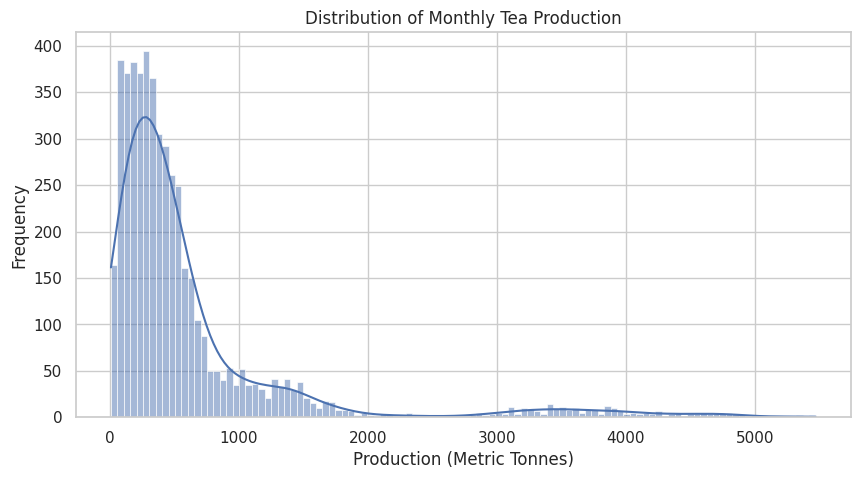

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=district_clean,
    x='production (t)',
    kde=True
)

plt.title('Distribution of Monthly Tea Production')
plt.xlabel('Production (Metric Tonnes)')
plt.ylabel('Frequency')

plt.show()

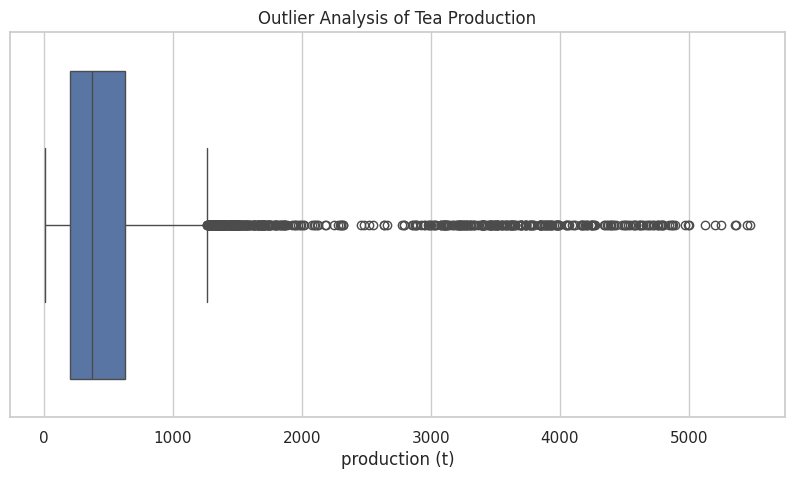

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=district_clean['production (t)']
)

plt.title('Outlier Analysis of Tea Production')

plt.show()

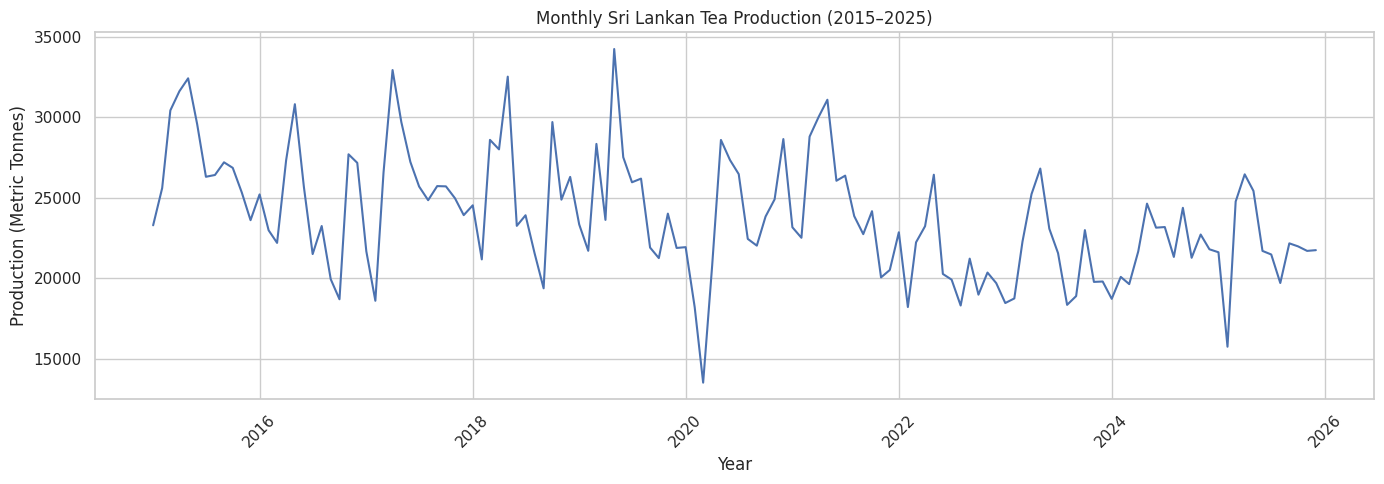

In [ ]:
national_monthly = (
    district_clean.groupby('month_start')['production (t)']
    .sum()
    .reset_index()
)

plt.figure(figsize=(14, 5))

plt.plot(
    national_monthly['month_start'],
    national_monthly['production (t)']
)

plt.title('Monthly Sri Lankan Tea Production (2015–2025)')
plt.xlabel('Year')
plt.ylabel('Production (Metric Tonnes)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

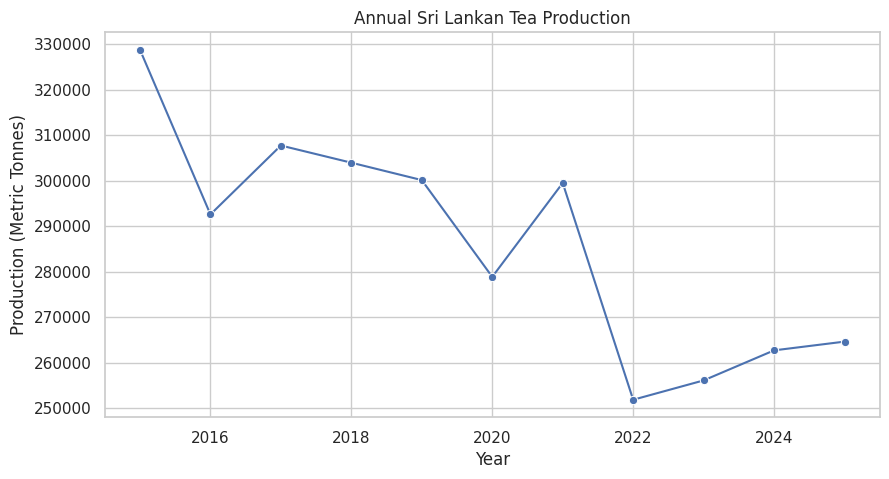

In [ ]:
annual_production = (
    district_clean.groupby('year')['production (t)']
    .sum()
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=annual_production,
    x='year',
    y='production (t)',
    marker='o'
)

plt.title('Annual Sri Lankan Tea Production')
plt.xlabel('Year')
plt.ylabel('Production (Metric Tonnes)')

plt.show()

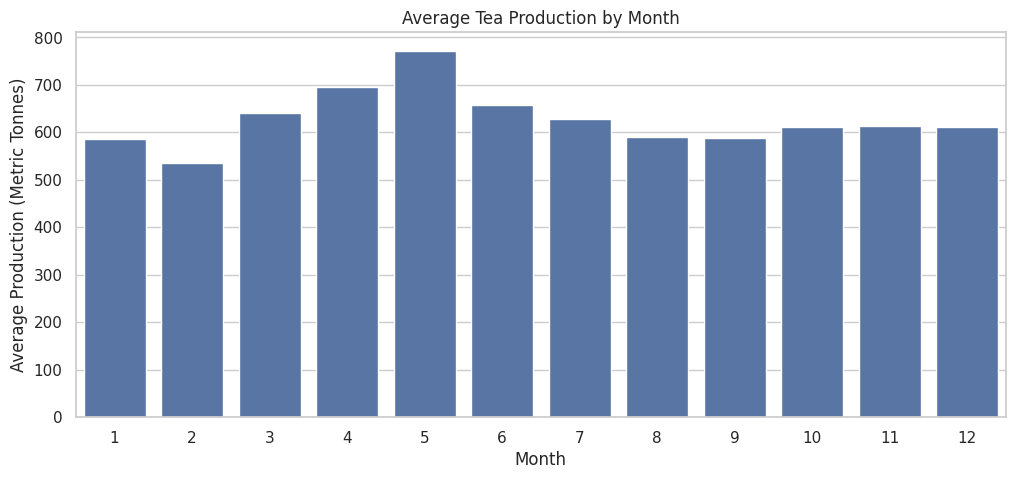

In [ ]:
monthly_average = (
    district_clean.groupby('month')['production (t)']
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=monthly_average,
    x='month',
    y='production (t)'
)

plt.title('Average Tea Production by Month')
plt.xlabel('Month')
plt.ylabel('Average Production (Metric Tonnes)')

plt.show()

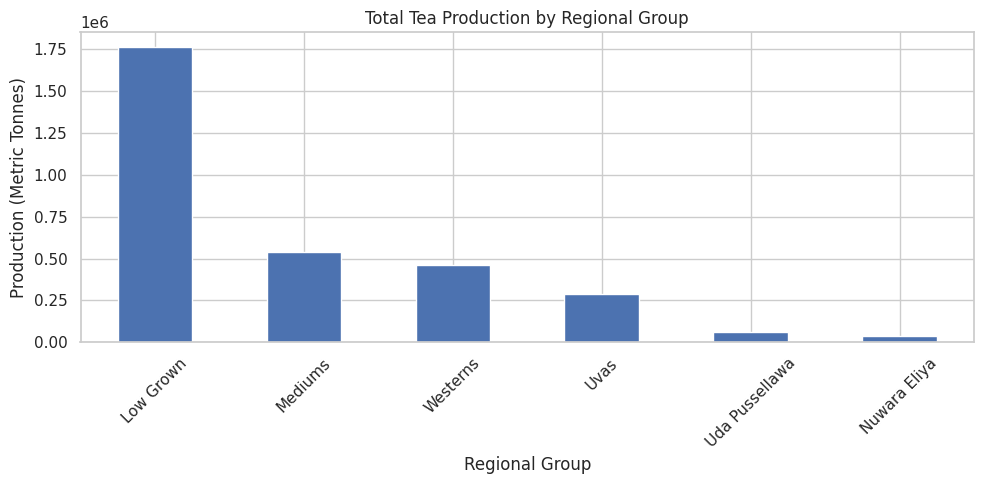

In [ ]:
regional_production = (
    district_clean.groupby('regional group')['production (t)']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

regional_production.plot(kind='bar')

plt.title('Total Tea Production by Regional Group')
plt.xlabel('Regional Group')
plt.ylabel('Production (Metric Tonnes)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

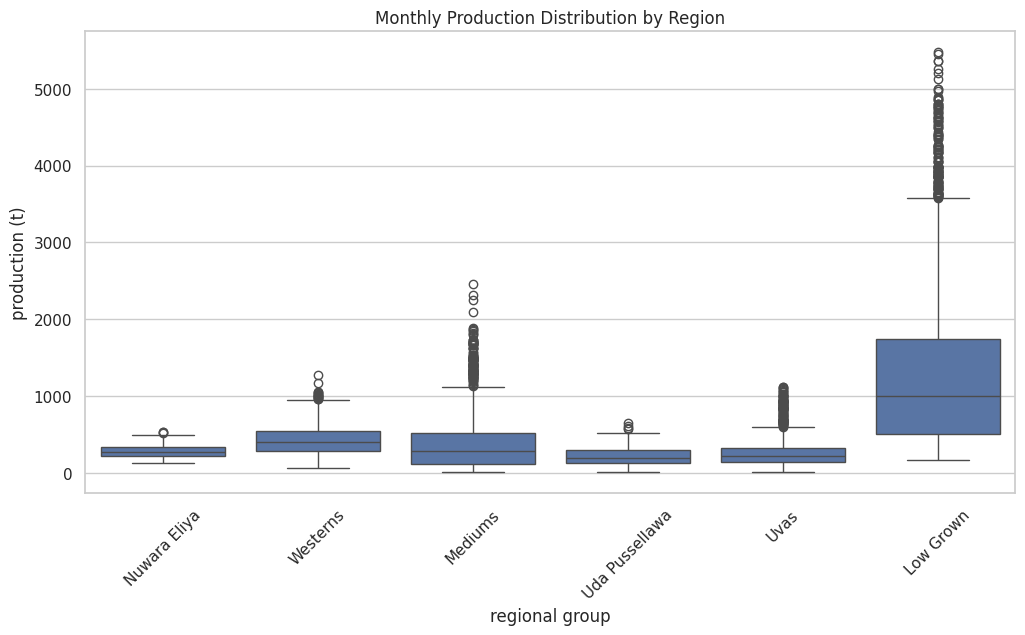

In [ ]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=district_clean,
    x='regional group',
    y='production (t)'
)

plt.title('Monthly Production Distribution by Region')
plt.xticks(rotation=45)

plt.show()

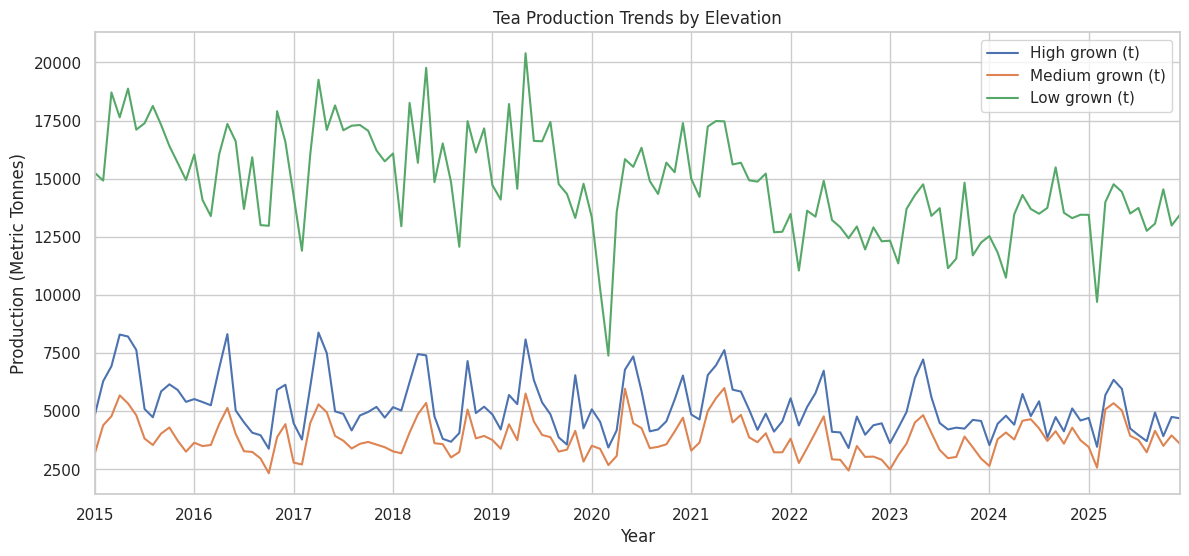

In [ ]:
elevation_clean.plot(
    x='month_start',
    y=[
        'High grown (t)',
        'Medium grown (t)',
        'Low grown (t)'
    ],
    figsize=(14, 6)
)

plt.title('Tea Production Trends by Elevation')
plt.xlabel('Year')
plt.ylabel('Production (Metric Tonnes)')

plt.show()

In [ ]:
elevation_columns = [
    'High grown (t)',
    'Medium grown (t)',
    'Low grown (t)'
]

display(
    elevation_clean[elevation_columns].mean()
)

,0
High grown (t),5206.165097
Medium grown (t),3865.888157
Low grown (t),14761.638243


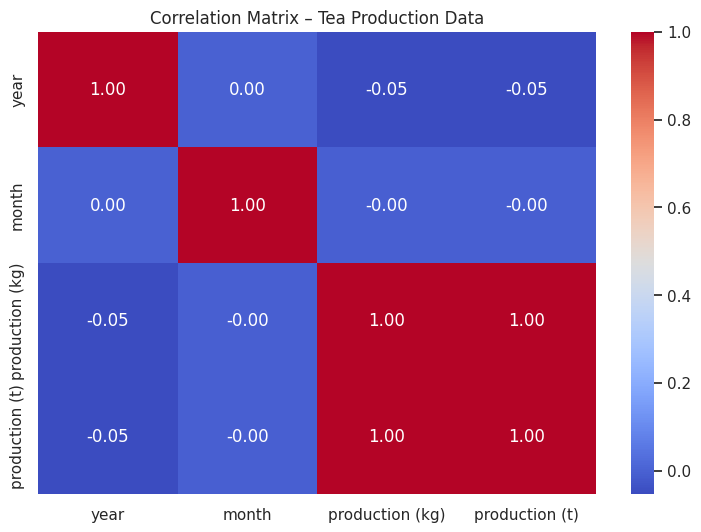

In [ ]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    district_clean[
        ['year', 'month', 'production (kg)', 'production (t)']
    ].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix – Tea Production Data')

plt.show()

## EDA to weather data set

In [ ]:
weather_eda = weather.copy()

# Convert Month to datetime if needed
weather_eda['Month'] = pd.to_datetime(
    weather_eda['Month']
)

# Display first five records
display(weather_eda.head())

,Month,Sub-district,Region (tea regional group),Area,Rainfall total (mm),Rainy days,Longest dry spell ending in period (days; may start in an earlier period),"Max temp, mean (°C)","Min temp, mean (°C)","Avg temp, mean (°C)","Relative humidity, mean (%)","Solar radiation, mean (MJ/m²/day)","Wind speed, mean (m/s)",ET0 total (mm),"Sunshine, mean (h/day)","Soil moisture 0-7 cm, mean (m³/m³)"
0,2015-01-01,Agarapathana,Westerns,High grown,21.569,3,25,21.738,14.921,17.923,79.250,18.282,0.701,96.482,6.921,0.400
1,2015-02-01,Agarapathana,Westerns,High grown,83.050,8,12,21.467,14.305,17.481,82.236,19.191,0.858,91.632,6.848,0.434
2,2015-03-01,Agarapathana,Westerns,High grown,90.464,13,8,22.765,14.789,18.446,78.629,22.732,0.683,121.070,8.613,0.420
3,2015-04-01,Agarapathana,Westerns,High grown,214.438,26,2,22.726,16.265,18.800,88.297,19.881,0.374,106.698,6.768,0.472
4,2015-05-01,Agarapathana,Westerns,High grown,232.712,18,9,22.614,17.332,19.282,90.310,18.845,1.397,104.725,6.482,0.478


In [ ]:
# Dataset dimensions

print("Number of Rows:", weather_eda.shape[0])
print("Number of Columns:", weather_eda.shape[1])

# Column names
print("\nColumn Names:")
print(weather_eda.columns.tolist())

# Data types
print("\nData Types:")
print(weather_eda.dtypes)

# Statistical summary
print("\nStatistical Summary:")
display(weather_eda.describe(include='all'))

Number of Rows: 5358
Number of Columns: 16

Column Names:
['Month', 'Sub-district', 'Region (tea regional group)', 'Area', 'Rainfall total (mm)', 'Rainy days', 'Longest dry spell ending in period (days; may start in an earlier period)', 'Max temp, mean (°C)', 'Min temp, mean (°C)', 'Avg temp, mean (°C)', 'Relative humidity, mean (%)', 'Solar radiation, mean (MJ/m²/day)', 'Wind speed, mean (m/s)', 'ET0 total (mm)', 'Sunshine, mean (h/day)', 'Soil moisture 0-7 cm, mean (m³/m³)']

Data Types:
Month                                                                        datetime64[ns]
Sub-district                                                                         object
Region (tea regional group)                                                          object
Area                                                                                 object
Rainfall total (mm)                                                                 float64
Rainy days                                   

,Month,Sub-district,Region (tea regional group),Area,Rainfall total (mm),Rainy days,Longest dry spell ending in period (days; may start in an earlier period),"Max temp, mean (°C)","Min temp, mean (°C)","Avg temp, mean (°C)","Relative humidity, mean (%)","Solar radiation, mean (MJ/m²/day)","Wind speed, mean (m/s)",ET0 total (mm),"Sunshine, mean (h/day)","Soil moisture 0-7 cm, mean (m³/m³)"
count,5358,5358,5358,5358,5358.000000,5358.000000,5358.000000,5358.000000,5358.000000,5358.000000,5358.000000,5358.000000,5358.000000,5358.000000,5358.000000,5358.000000
unique,NaN,38,6,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Agarapathana,Mediums,High grown,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,141,1410,1551,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2020-10-31 01:11:29.361702144,NaN,NaN,NaN,226.115926,15.225644,8.104517,25.765422,19.407396,22.160907,84.095193,18.447311,1.346781,107.309394,6.405950,0.419699
min,2015-01-01 00:00:00,NaN,NaN,NaN,9.801000,1.000000,0.000000,20.571000,14.089000,17.131000,57.218000,10.849000,0.222000,65.161000,2.523000,0.155000
25%,2017-12-01 00:00:00,NaN,NaN,NaN,107.647500,10.000000,4.000000,23.539250,17.556000,20.069000,81.184000,16.776250,0.765250,95.712250,5.459500,0.388000
50%,2020-11-01 00:00:00,NaN,NaN,NaN,192.128000,15.000000,7.000000,25.887500,19.304500,22.251000,85.529500,18.632000,1.167500,107.323500,6.541000,0.438000
75%,2023-10-01 00:00:00,NaN,NaN,NaN,308.523500,20.000000,11.000000,27.752000,21.112500,24.062500,88.536750,20.155250,1.821500,118.496500,7.335000,0.467000
max,2026-09-01 00:00:00,NaN,NaN,NaN,1261.195000,31.000000,40.000000,33.962000,25.442000,28.235000,93.006000,24.403000,4.770000,161.934000,9.713000,0.495000


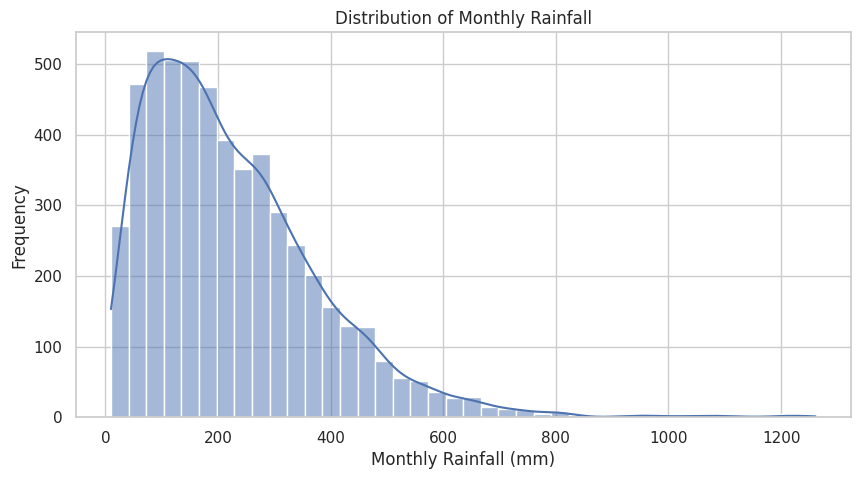

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    weather_eda['Rainfall total (mm)'],
    bins=40,
    kde=True
)

plt.title('Distribution of Monthly Rainfall')
plt.xlabel('Monthly Rainfall (mm)')
plt.ylabel('Frequency')

plt.show()

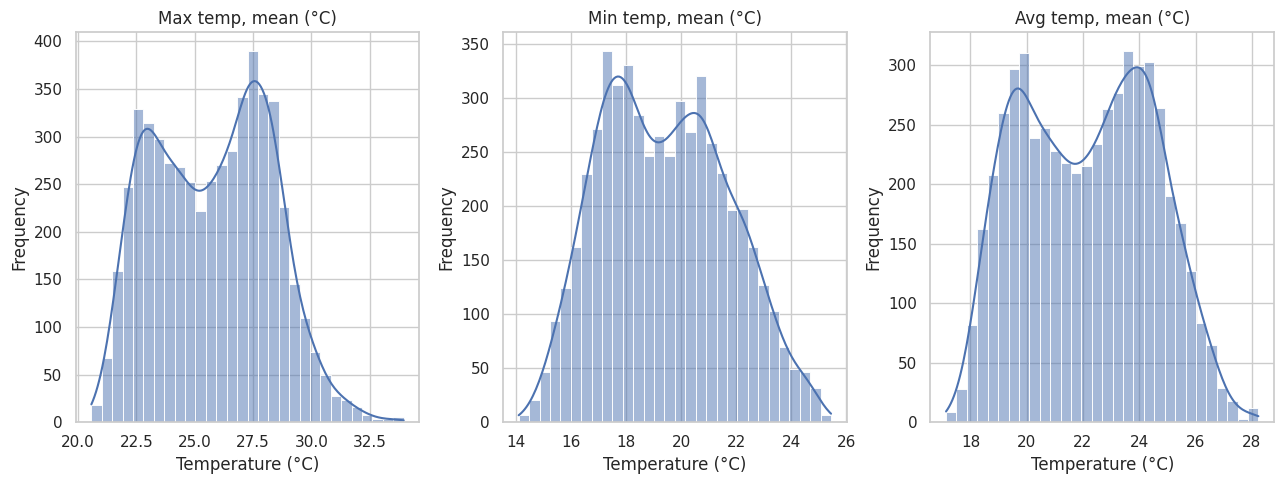

In [ ]:
temperature_columns = [
    'Max temp, mean (°C)',
    'Min temp, mean (°C)',
    'Avg temp, mean (°C)'
]

plt.figure(figsize=(13, 5))

for i, col in enumerate(temperature_columns, 1):

    plt.subplot(1, 3, i)

    sns.histplot(
        weather_eda[col],
        bins=30,
        kde=True
    )

    plt.title(col)
    plt.xlabel('Temperature (°C)')
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

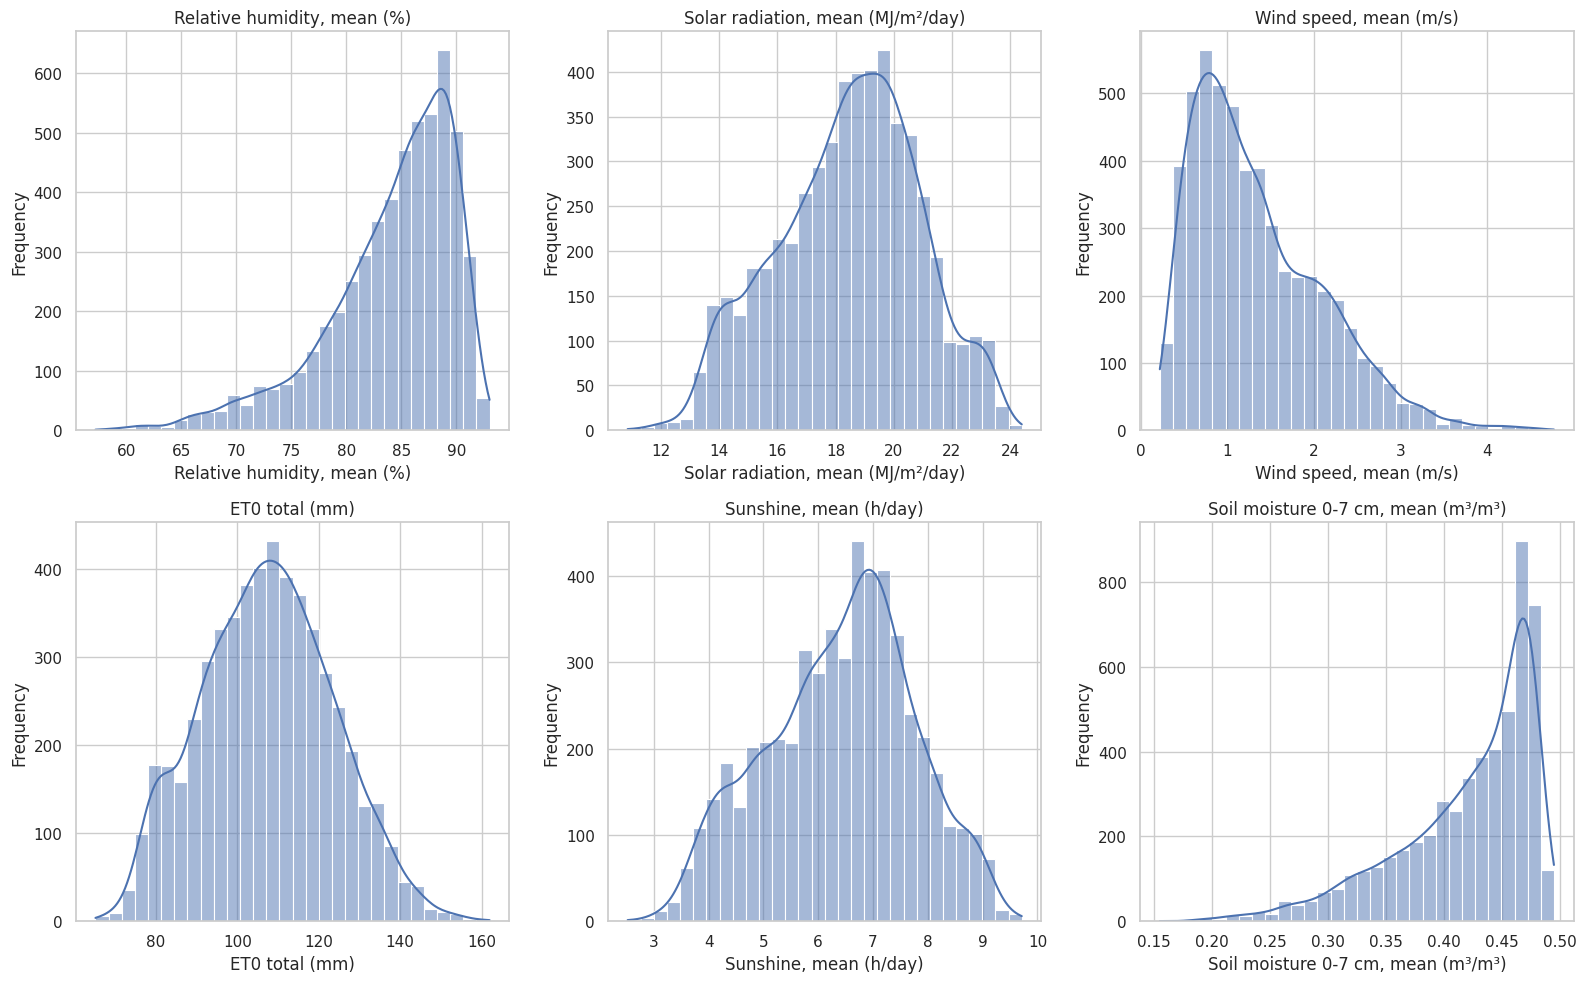

In [ ]:
other_weather_columns = [
    'Relative humidity, mean (%)',
    'Solar radiation, mean (MJ/m²/day)',
    'Wind speed, mean (m/s)',
    'ET0 total (mm)',
    'Sunshine, mean (h/day)',
    'Soil moisture 0-7 cm, mean (m³/m³)'
]

plt.figure(figsize=(16, 10))

for i, col in enumerate(other_weather_columns, 1):

    plt.subplot(2, 3, i)

    sns.histplot(
        weather_eda[col],
        bins=30,
        kde=True
    )

    plt.title(col)
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

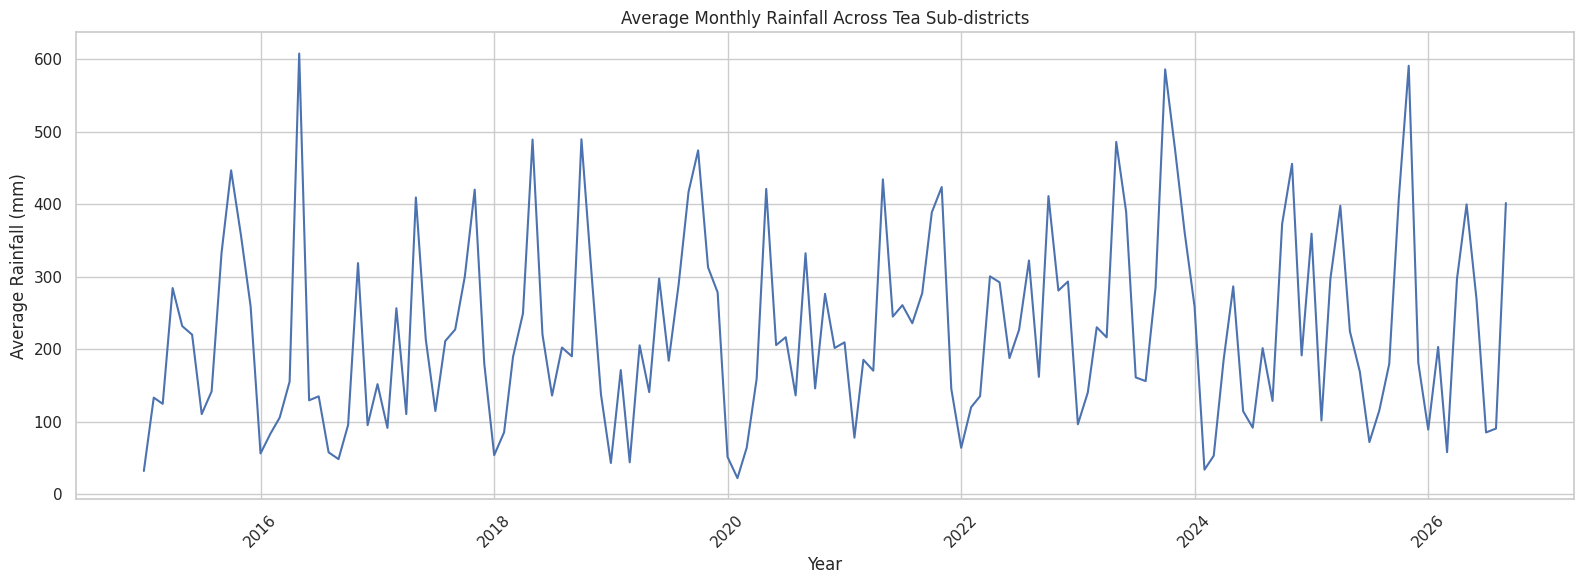

In [ ]:
# Aggregate rainfall across sub-districts for each month

monthly_rainfall = (
    weather_eda.groupby('Month')['Rainfall total (mm)']
    .mean()
    .reset_index()
)

plt.figure(figsize=(16, 6))

plt.plot(
    monthly_rainfall['Month'],
    monthly_rainfall['Rainfall total (mm)'],
    linewidth=1.5
)

plt.title('Average Monthly Rainfall Across Tea Sub-districts')
plt.xlabel('Year')
plt.ylabel('Average Rainfall (mm)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

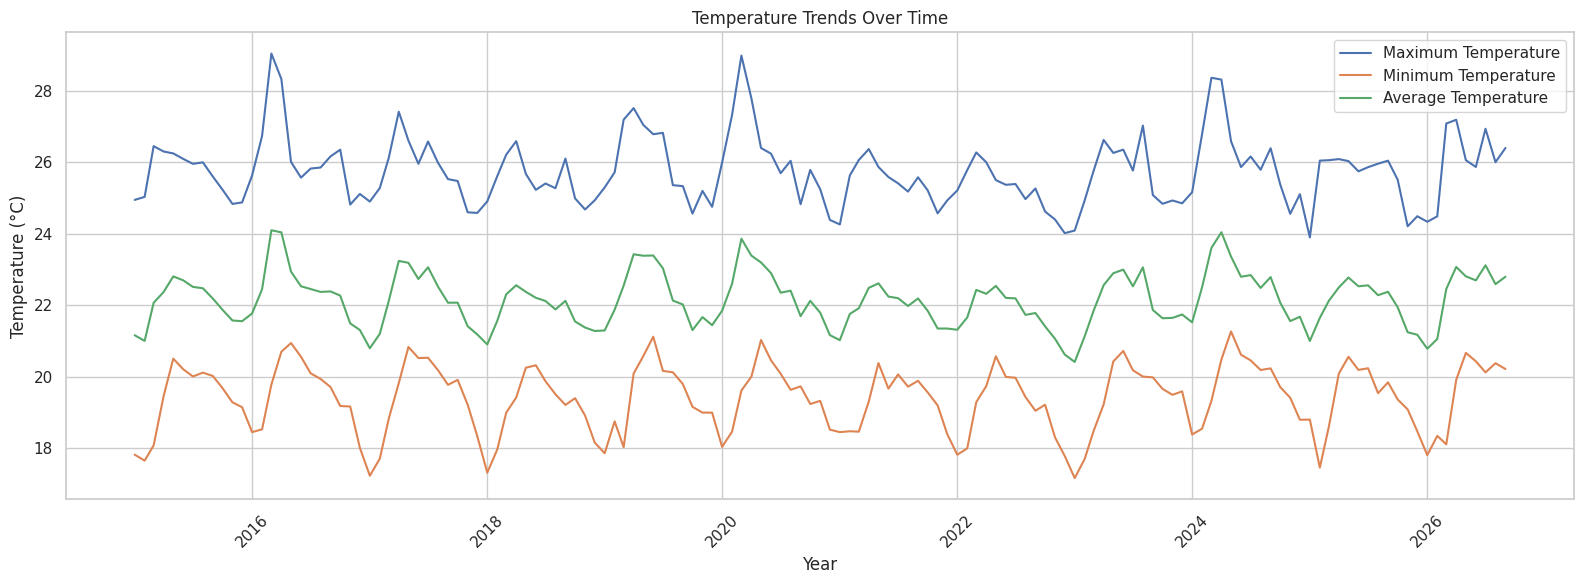

In [ ]:
# Aggregate temperature variables by month

monthly_temperature = (
    weather_eda.groupby('Month')[
        [
            'Max temp, mean (°C)',
            'Min temp, mean (°C)',
            'Avg temp, mean (°C)'
        ]
    ]
    .mean()
    .reset_index()
)

plt.figure(figsize=(16, 6))

plt.plot(
    monthly_temperature['Month'],
    monthly_temperature['Max temp, mean (°C)'],
    label='Maximum Temperature'
)

plt.plot(
    monthly_temperature['Month'],
    monthly_temperature['Min temp, mean (°C)'],
    label='Minimum Temperature'
)

plt.plot(
    monthly_temperature['Month'],
    monthly_temperature['Avg temp, mean (°C)'],
    label='Average Temperature'
)

plt.title('Temperature Trends Over Time')
plt.xlabel('Year')
plt.ylabel('Temperature (°C)')

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

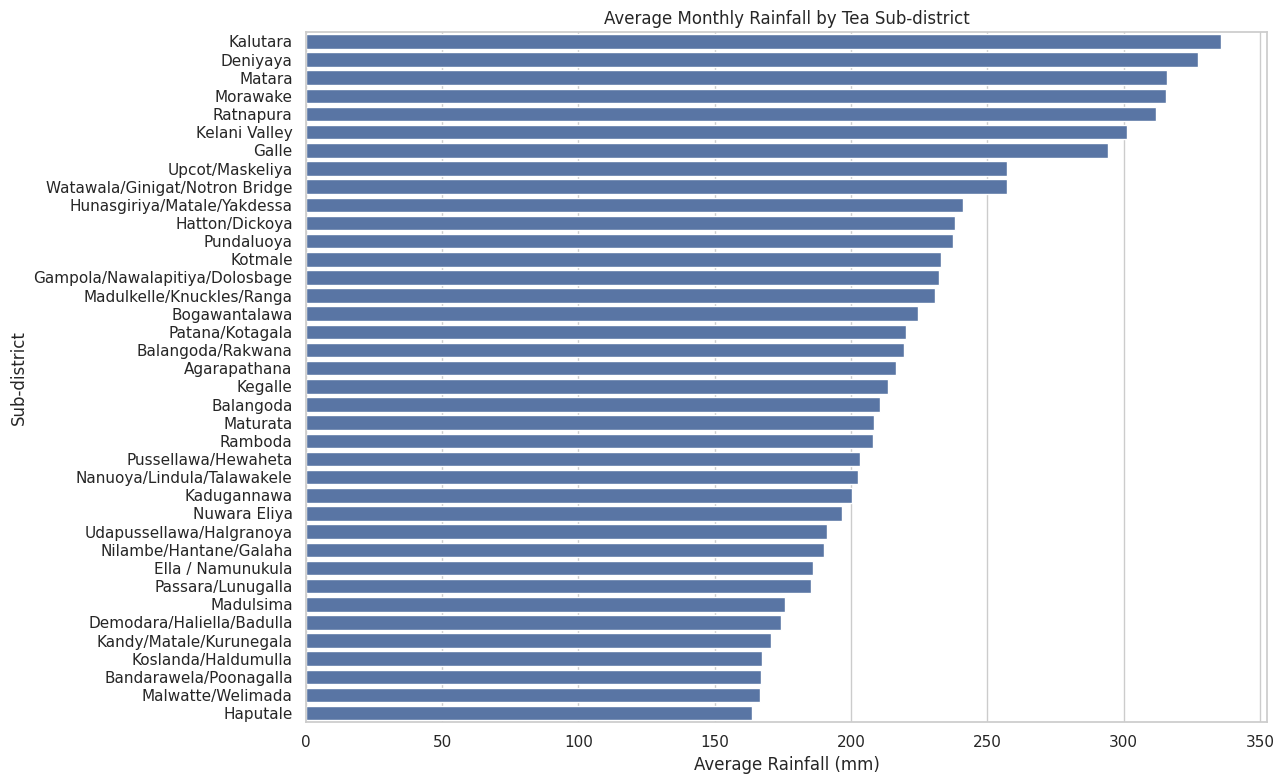

In [ ]:
# Calculate average rainfall by sub-district

district_rainfall = (
    weather_eda.groupby('Sub-district')[
        'Rainfall total (mm)'
    ]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(13, 8))

sns.barplot(
    x=district_rainfall.values,
    y=district_rainfall.index
)

plt.title('Average Monthly Rainfall by Tea Sub-district')
plt.xlabel('Average Rainfall (mm)')
plt.ylabel('Sub-district')

plt.tight_layout()
plt.show()

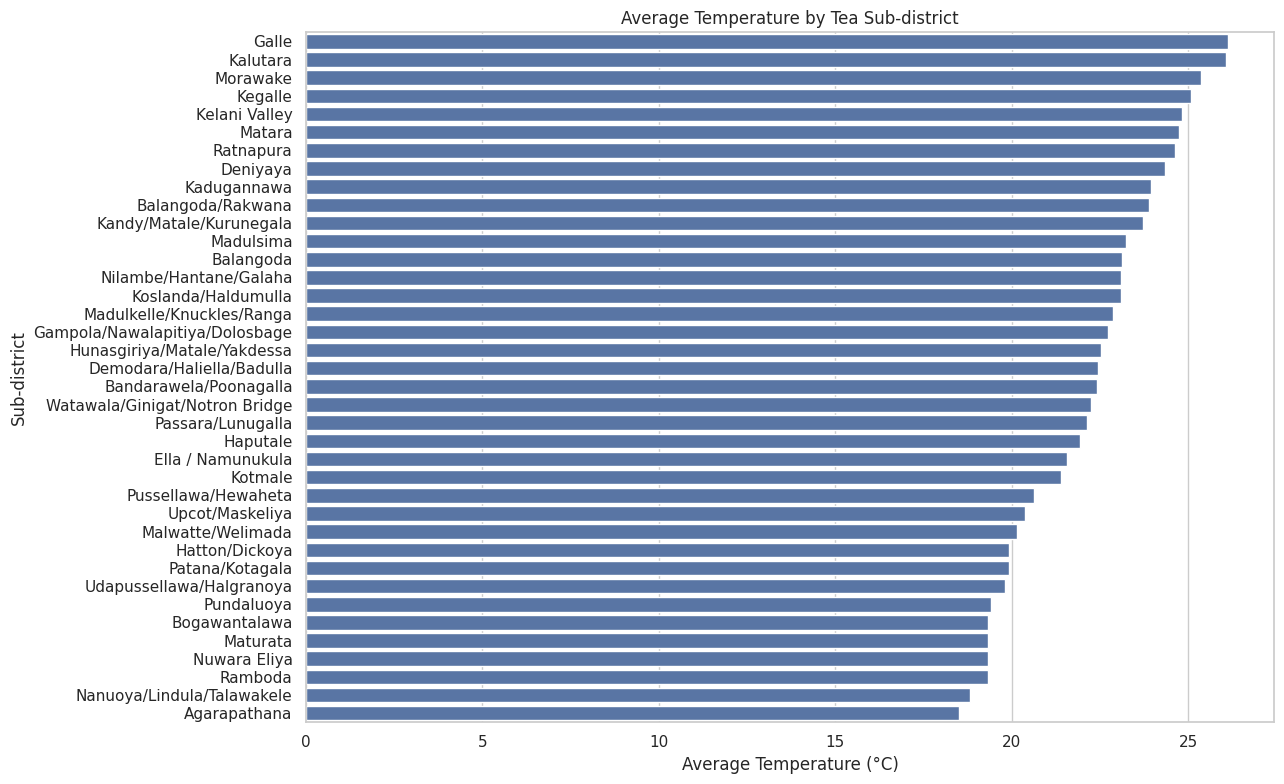

In [ ]:
district_temperature = (
    weather_eda.groupby('Sub-district')[
        'Avg temp, mean (°C)'
    ]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(13, 8))

sns.barplot(
    x=district_temperature.values,
    y=district_temperature.index
)

plt.title('Average Temperature by Tea Sub-district')
plt.xlabel('Average Temperature (°C)')
plt.ylabel('Sub-district')

plt.tight_layout()
plt.show()

In [ ]:
# Average weather conditions by region

region_weather = (
    weather_eda.groupby('Region (tea regional group)')[
        [
            'Rainfall total (mm)',
            'Avg temp, mean (°C)',
            'Relative humidity, mean (%)',
            'Soil moisture 0-7 cm, mean (m³/m³)'
        ]
    ]
    .mean()
    .round(2)
)

display(region_weather)

,Rainfall total (mm),"Avg temp, mean (°C)","Relative humidity, mean (%)","Soil moisture 0-7 cm, mean (m³/m³)"
Region (tea regional group),,,,
Low Grown,291.77,24.91,85.51,0.43
Mediums,217.83,22.70,84.09,0.41
Nuwara Eliya,196.86,19.32,83.66,0.43
Uda Pussellawa,199.77,19.56,83.27,0.43
Uvas,173.34,22.12,80.28,0.38
Westerns,225.63,19.45,86.58,0.45


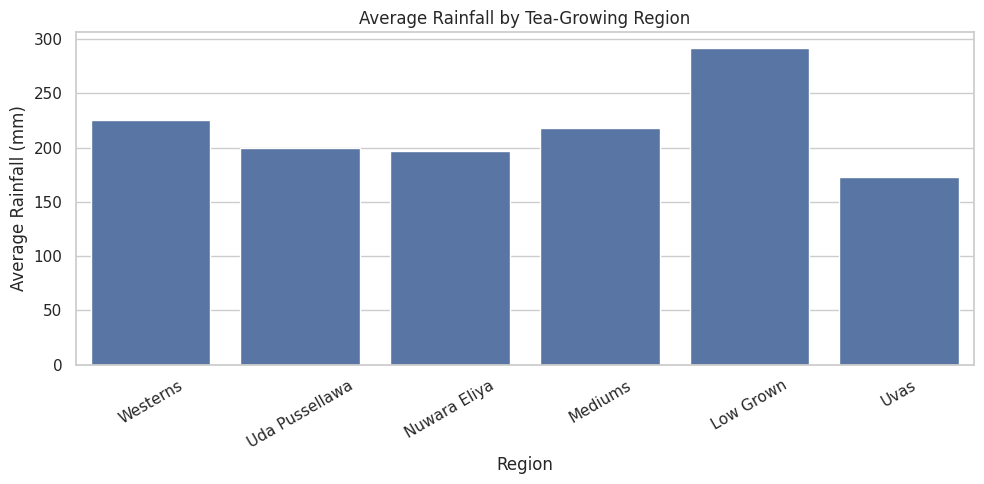

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=weather_eda,
    x='Region (tea regional group)',
    y='Rainfall total (mm)',
    errorbar=None
)

plt.title('Average Rainfall by Tea-Growing Region')
plt.xlabel('Region')
plt.ylabel('Average Rainfall (mm)')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

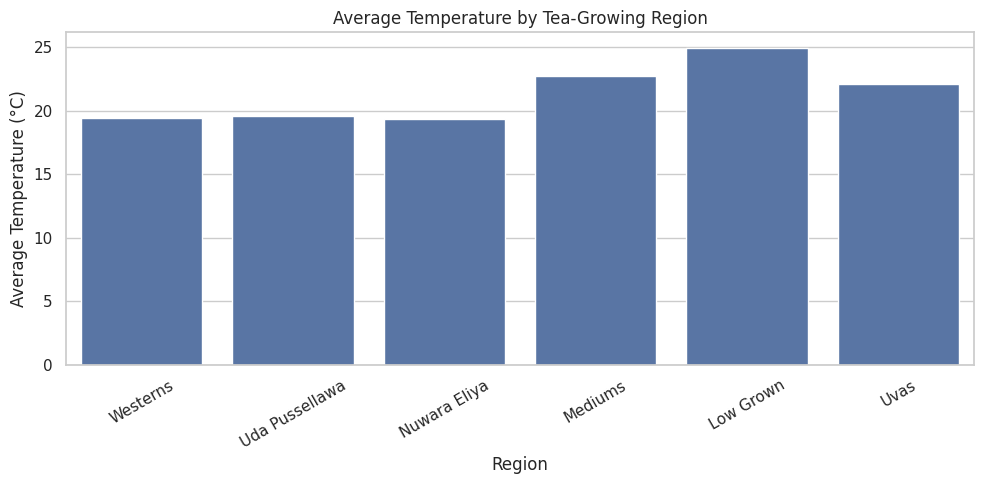

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=weather_eda,
    x='Region (tea regional group)',
    y='Avg temp, mean (°C)',
    errorbar=None
)

plt.title('Average Temperature by Tea-Growing Region')
plt.xlabel('Region')
plt.ylabel('Average Temperature (°C)')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

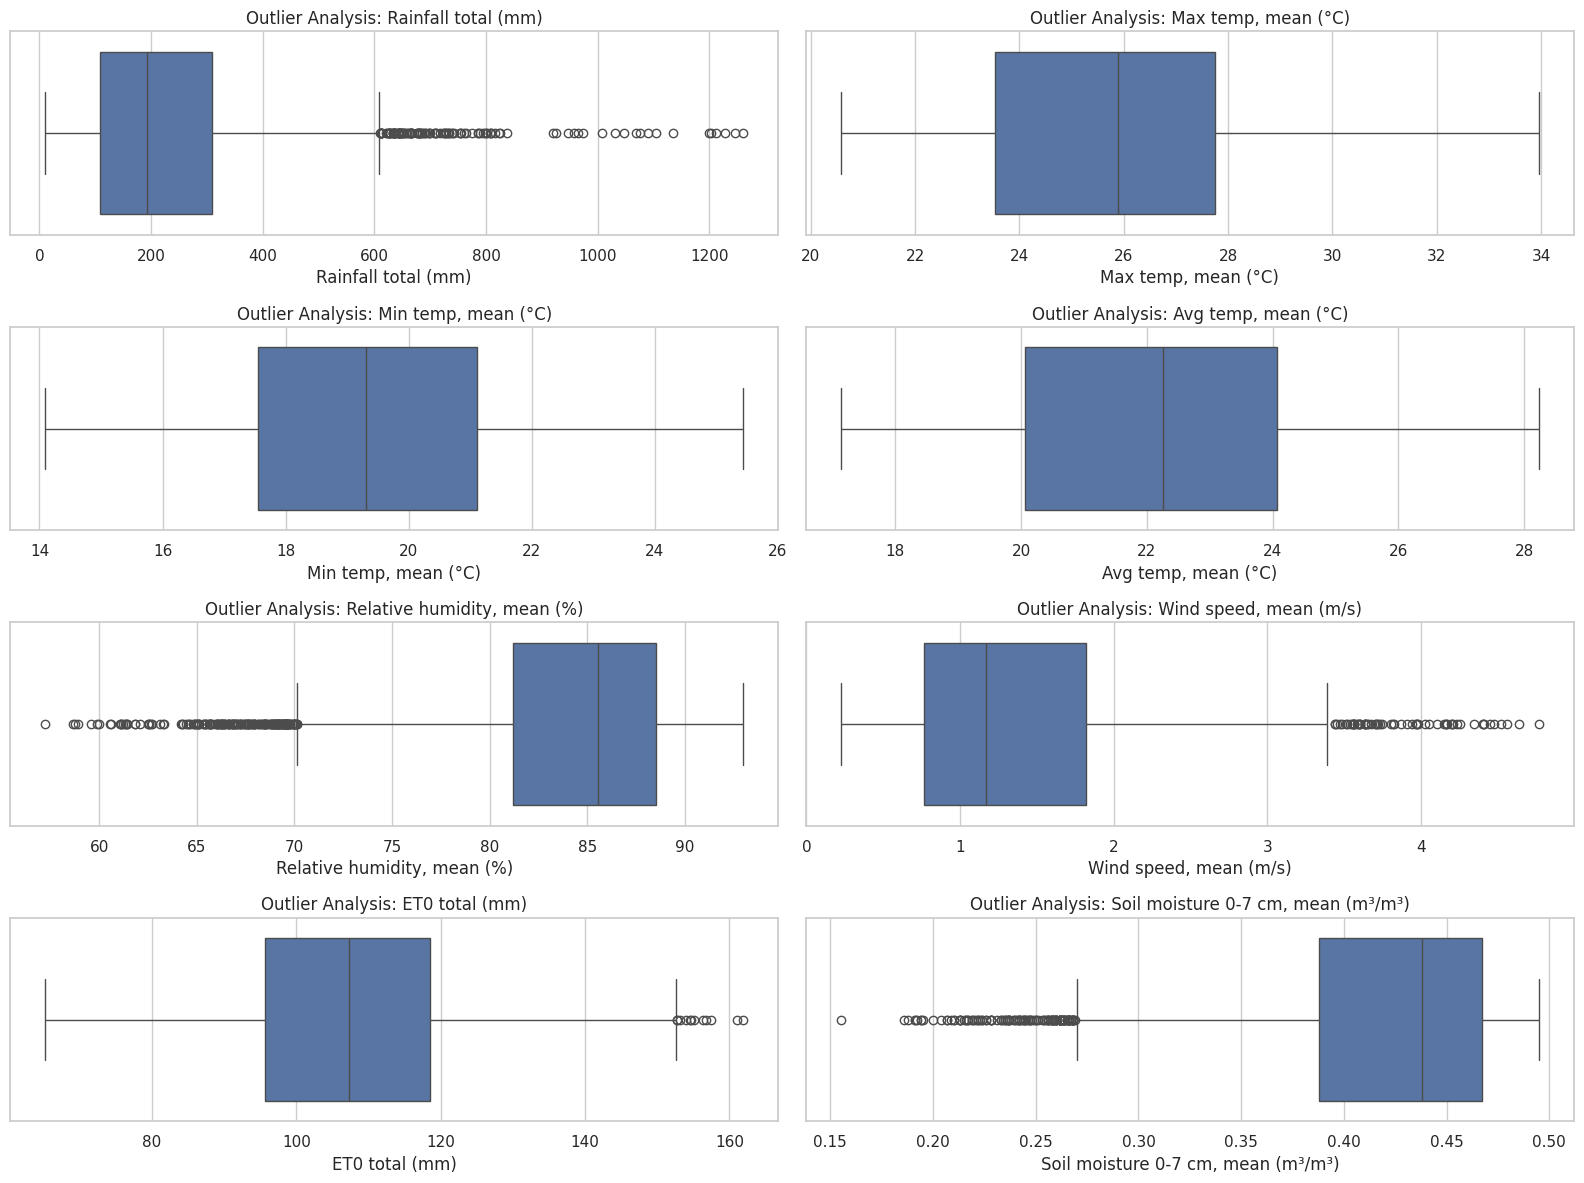

In [ ]:
weather_columns = [
    'Rainfall total (mm)',
    'Max temp, mean (°C)',
    'Min temp, mean (°C)',
    'Avg temp, mean (°C)',
    'Relative humidity, mean (%)',
    'Wind speed, mean (m/s)',
    'ET0 total (mm)',
    'Soil moisture 0-7 cm, mean (m³/m³)'
]

plt.figure(figsize=(16, 12))

for i, col in enumerate(weather_columns, 1):

    plt.subplot(4, 2, i)

    sns.boxplot(
        x=weather_eda[col]
    )

    plt.title(f'Outlier Analysis: {col}')
    plt.xlabel(col)

plt.tight_layout()
plt.show()

In [ ]:
# Select numerical weather variables

correlation_columns = [
    'Rainfall total (mm)',
    'Max temp, mean (°C)',
    'Min temp, mean (°C)',
    'Avg temp, mean (°C)',
    'Relative humidity, mean (%)',
    'Wind speed, mean (m/s)',
    'ET0 total (mm)',
    'Soil moisture 0-7 cm, mean (m³/m³)'
]

# Calculate correlation matrix

weather_corr = weather_eda[
    correlation_columns
].corr()

# Display correlation matrix

display(weather_corr.round(2))

,Rainfall total (mm),"Max temp, mean (°C)","Min temp, mean (°C)","Avg temp, mean (°C)","Relative humidity, mean (%)","Wind speed, mean (m/s)",ET0 total (mm),"Soil moisture 0-7 cm, mean (m³/m³)"
Rainfall total (mm),1.00,-0.03,0.27,0.09,0.58,-0.04,-0.42,0.51
"Max temp, mean (°C)",-0.03,1.00,0.84,0.97,-0.43,0.04,0.64,-0.47
"Min temp, mean (°C)",0.27,0.84,1.00,0.95,0.01,0.31,0.37,-0.09
"Avg temp, mean (°C)",0.09,0.97,0.95,1.00,-0.24,0.16,0.53,-0.32
"Relative humidity, mean (%)",0.58,-0.43,0.01,-0.24,1.00,0.05,-0.70,0.84
"Wind speed, mean (m/s)",-0.04,0.04,0.31,0.16,0.05,1.00,0.23,-0.05
ET0 total (mm),-0.42,0.64,0.37,0.53,-0.70,0.23,1.00,-0.63
"Soil moisture 0-7 cm, mean (m³/m³)",0.51,-0.47,-0.09,-0.32,0.84,-0.05,-0.63,1.00


In [ ]:
# Summary of weather conditions by region

weather_summary = (
    weather_eda.groupby('Region (tea regional group)')
    .agg({
        'Rainfall total (mm)': ['mean', 'min', 'max', 'std'],
        'Avg temp, mean (°C)': ['mean', 'min', 'max', 'std'],
        'Relative humidity, mean (%)': ['mean', 'min', 'max'],
        'Soil moisture 0-7 cm, mean (m³/m³)': ['mean', 'min', 'max'],
        'Wind speed, mean (m/s)': ['mean', 'min', 'max']
    })
)

display(weather_summary.round(2))

Rainfall total (mm)                          \
                                           mean    min      max     std   
Region (tea regional group)                                               
Low Grown                                291.77   9.80  1261.20  202.52   
Mediums                                  217.83  10.26   808.63  137.56   
Nuwara Eliya                             196.86  17.63   500.03  113.71   
Uda Pussellawa                           199.77  21.81   664.86  123.58   
Uvas                                     173.34  11.97   661.40  120.94   
Westerns                                 225.63  12.43   685.95  133.85   

                            Avg temp, mean (°C)                      \
                                           mean    min    max   std   
Region (tea regional group)                                           
Low Grown                                 24.91  21.77  28.24  1.11   
Mediums                                   22.70  18.70  26.86  1.34   
Nuwara Eliya                              19.32  17.47  21.24  0.81   
Uda Pussellawa                            19.56  17.46  21.59  0.88   
Uvas                                      22.12  18.00  26.25  1.53   
Westerns                                  19.45  17.13  22.12  0.85   

                            Relative humidity, mean (%)                \
                                                   mean    min    max   
Region (tea regional group)                                             
Low Grown                                         85.51  59.96  92.47   
Mediums                                           84.09  63.10  92.64   
Nuwara Eliya                                      83.66  65.11  91.84   
Uda Pussellawa                                    83.27  65.14  91.83   
Uvas                                              80.28  57.22  91.74   
Westerns                                          86.58  64.23  93.01   

                            Soil moisture 0-7 cm, mean (m³/m³)              \
                                                          mean   min   max   
Region (tea regional group)                                                  
Low Grown                                                 0.43  0.22  0.49   
Mediums                                                   0.41  0.19  0.49   
Nuwara Eliya                                              0.43  0.29  0.48   
Uda Pussellawa                                            0.43  0.29  0.48   
Uvas                                                      0.38  0.16  0.48   
Westerns                                                  0.45  0.31  0.50   

                            Wind speed, mean (m/s)              
                                              mean   min   max  
Region (tea regional group)                                     
Low Grown                                     1.51  0.22  4.77  
Mediums                                       1.39  0.23  3.63  
Nuwara Eliya                                  1.37  0.33  2.60  
Uda Pussellawa                                1.34  0.33  2.60  
Uvas                                          1.22  0.34  2.85  
Westerns                                      1.23  0.25  2.99

In [ ]:
# Overall weather statistics

weather_statistics = weather_eda[
    correlation_columns
].agg([
    'mean',
    'median',
    'std',
    'min',
    'max'
]).T

weather_statistics.columns = [
    'Mean',
    'Median',
    'Standard Deviation',
    'Minimum',
    'Maximum'
]

display(weather_statistics.round(2))

,Mean,Median,Standard Deviation,Minimum,Maximum
Rainfall total (mm),226.12,192.13,156.06,9.80,1261.20
"Max temp, mean (°C)",25.77,25.89,2.52,20.57,33.96
"Min temp, mean (°C)",19.41,19.30,2.30,14.09,25.44
"Avg temp, mean (°C)",22.16,22.25,2.34,17.13,28.24
"Relative humidity, mean (%)",84.10,85.53,5.85,57.22,93.01
"Wind speed, mean (m/s)",1.35,1.17,0.75,0.22,4.77
ET0 total (mm),107.31,107.32,16.19,65.16,161.93
"Soil moisture 0-7 cm, mean (m³/m³)",0.42,0.44,0.06,0.16,0.50


## EDA for combined tea and weather data

In [ ]:
print('district_clean exists:', 'district_clean' in globals())
print('weather_eda exists:', 'weather_eda' in globals())

district_clean exists: True
weather_eda exists: True


In [ ]:
# Create copies of the cleaned datasets

tea_merged = district_clean.copy()

weather_merged = weather_eda.copy()

# Standardise date columns

tea_merged['month_start'] = pd.to_datetime(
    tea_merged['month_start']
).dt.to_period('M').dt.to_timestamp()

weather_merged['Month'] = pd.to_datetime(
    weather_merged['Month']
).dt.to_period('M').dt.to_timestamp()

# Standardise location names

tea_merged['district'] = (
    tea_merged['district'].astype(str).str.strip()
)

weather_merged['Sub-district'] = (
    weather_merged['Sub-district'].astype(str).str.strip()
)

# Display date ranges

print("Tea date range:",
      tea_merged['month_start'].min(),
      "to",
      tea_merged['month_start'].max())

print("Weather date range:",
      weather_merged['Month'].min(),
      "to",
      weather_merged['Month'].max())

Tea date range: 2015-01-01 00:00:00 to 2025-12-01 00:00:00
Weather date range: 2015-01-01 00:00:00 to 2026-09-01 00:00:00


In [ ]:
# Get unique location names

tea_locations = set(tea_merged['district'].unique())

weather_locations = set(
    weather_merged['Sub-district'].unique()
)

# Compare location names

print("Tea locations:", len(tea_locations))
print("Weather locations:", len(weather_locations))

print("\nLocations only in Tea Dataset:")
print(sorted(tea_locations - weather_locations))

print("\nLocations only in Weather Dataset:")
print(sorted(weather_locations - tea_locations))

print("\nLocations matching:",
      len(tea_locations & weather_locations))

Tea locations: 38
Weather locations: 38

Locations only in Tea Dataset:
[]

Locations only in Weather Dataset:
[]

Locations matching: 38


In [ ]:
# Merge tea production and weather datasets

combined_df = pd.merge(
    tea_merged,
    weather_merged,
    left_on=['month_start', 'district'],
    right_on=['Month', 'Sub-district'],
    how='inner',
    validate='one_to_one'
)

# Remove redundant columns

combined_df.drop(
    columns=['Month', 'Sub-district'],
    inplace=True
)

# Display the combined dataset

print("Combined Dataset Shape:", combined_df.shape)

display(combined_df.head())

Combined Dataset Shape: (5016, 23)


,month_start,year,month,district,regional group,production (kg),production (t),unit_difference,2017_discrepancy_period,Region (tea regional group),Area,Rainfall total (mm),Rainy days,Longest dry spell ending in period (days; may start in an earlier period),"Max temp, mean (°C)","Min temp, mean (°C)","Avg temp, mean (°C)","Relative humidity, mean (%)","Solar radiation, mean (MJ/m²/day)","Wind speed, mean (m/s)",ET0 total (mm),"Sunshine, mean (h/day)","Soil moisture 0-7 cm, mean (m³/m³)"
0,2015-01-01,2015,1,Nuwara Eliya,Nuwara Eliya,240949.5,240.9495,0.0,False,Nuwara Eliya,High grown,23.450,4,20,21.942,15.393,18.280,80.318,17.987,0.982,97.112,6.734,0.373
1,2015-01-01,2015,1,Agarapathana,Westerns,723975.0,723.9750,0.0,False,Westerns,High grown,21.569,3,25,21.738,14.921,17.923,79.250,18.282,0.701,96.482,6.921,0.400
2,2015-01-01,2015,1,Bogawantalawa,Westerns,458924.0,458.9240,0.0,False,Westerns,High grown,25.958,2,28,22.393,15.513,18.605,80.689,18.397,0.495,97.350,6.989,0.418
3,2015-01-01,2015,1,Hatton/Dickoya,Westerns,603749.0,603.7490,0.0,False,Westerns,High grown,19.422,3,25,23.138,16.296,19.411,80.420,18.415,0.572,98.952,7.019,0.417
4,2015-01-01,2015,1,Nanuoya/Lindula/Talawakele,Westerns,681714.5,681.7145,0.0,False,Westerns,High grown,22.131,3,25,21.933,15.151,18.148,79.312,18.202,0.865,97.018,6.880,0.384


In [ ]:
# Check missing values

display(combined_df.isnull().sum())

# Check duplicate records

print(
    "Duplicate rows:",
    combined_df.duplicated(
        subset=['month_start', 'district']
    ).sum()
)

# Check date coverage

print("Start Date:", combined_df['month_start'].min())
print("End Date:", combined_df['month_start'].max())

# Check number of districts

print("Number of districts:",
      combined_df['district'].nunique())

,0
month_start,0
year,0
month,0
district,0
regional group,0
production (kg),0
production (t),0
unit_difference,0
2017_discrepancy_period,0
Region (tea regional group),0


Duplicate rows: 0
Start Date: 2015-01-01 00:00:00
End Date: 2025-12-01 00:00:00
Number of districts: 38


,production (t),Rainfall total (mm),"Avg temp, mean (°C)","Relative humidity, mean (%)","Soil moisture 0-7 cm, mean (m³/m³)","Wind speed, mean (m/s)",ET0 total (mm),"Sunshine, mean (h/day)"
production (t),1.00,0.20,0.43,0.17,0.12,0.07,0.08,-0.02
Rainfall total (mm),0.20,1.00,0.08,0.59,0.51,-0.05,-0.43,-0.65
"Avg temp, mean (°C)",0.43,0.08,1.00,-0.24,-0.32,0.15,0.53,0.21
"Relative humidity, mean (%)",0.17,0.59,-0.24,1.00,0.84,0.05,-0.70,-0.72
"Soil moisture 0-7 cm, mean (m³/m³)",0.12,0.51,-0.32,0.84,1.00,-0.05,-0.62,-0.62
"Wind speed, mean (m/s)",0.07,-0.05,0.15,0.05,-0.05,1.00,0.23,0.03
ET0 total (mm),0.08,-0.43,0.53,-0.70,-0.62,0.23,1.00,0.84
"Sunshine, mean (h/day)",-0.02,-0.65,0.21,-0.72,-0.62,0.03,0.84,1.00


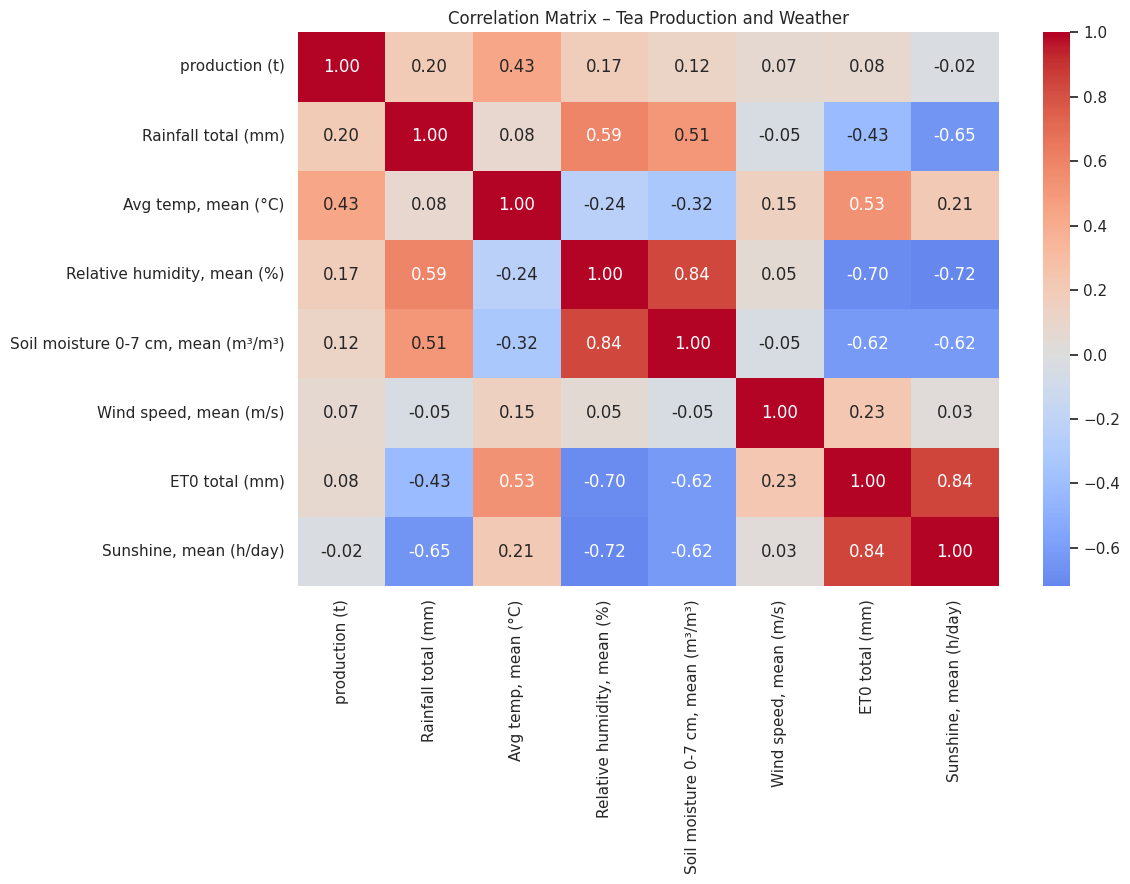

In [ ]:
# Select important variables

combined_columns = [
    'production (t)',
    'Rainfall total (mm)',
    'Avg temp, mean (°C)',
    'Relative humidity, mean (%)',
    'Soil moisture 0-7 cm, mean (m³/m³)',
    'Wind speed, mean (m/s)',
    'ET0 total (mm)',
    'Sunshine, mean (h/day)'
]

# Calculate correlations

combined_corr = combined_df[
    combined_columns
].corr()

# Display correlation matrix

display(combined_corr.round(2))

# Visualise correlations

plt.figure(figsize=(12, 9))

sns.heatmap(
    combined_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Correlation Matrix – Tea Production and Weather')

plt.tight_layout()
plt.show()

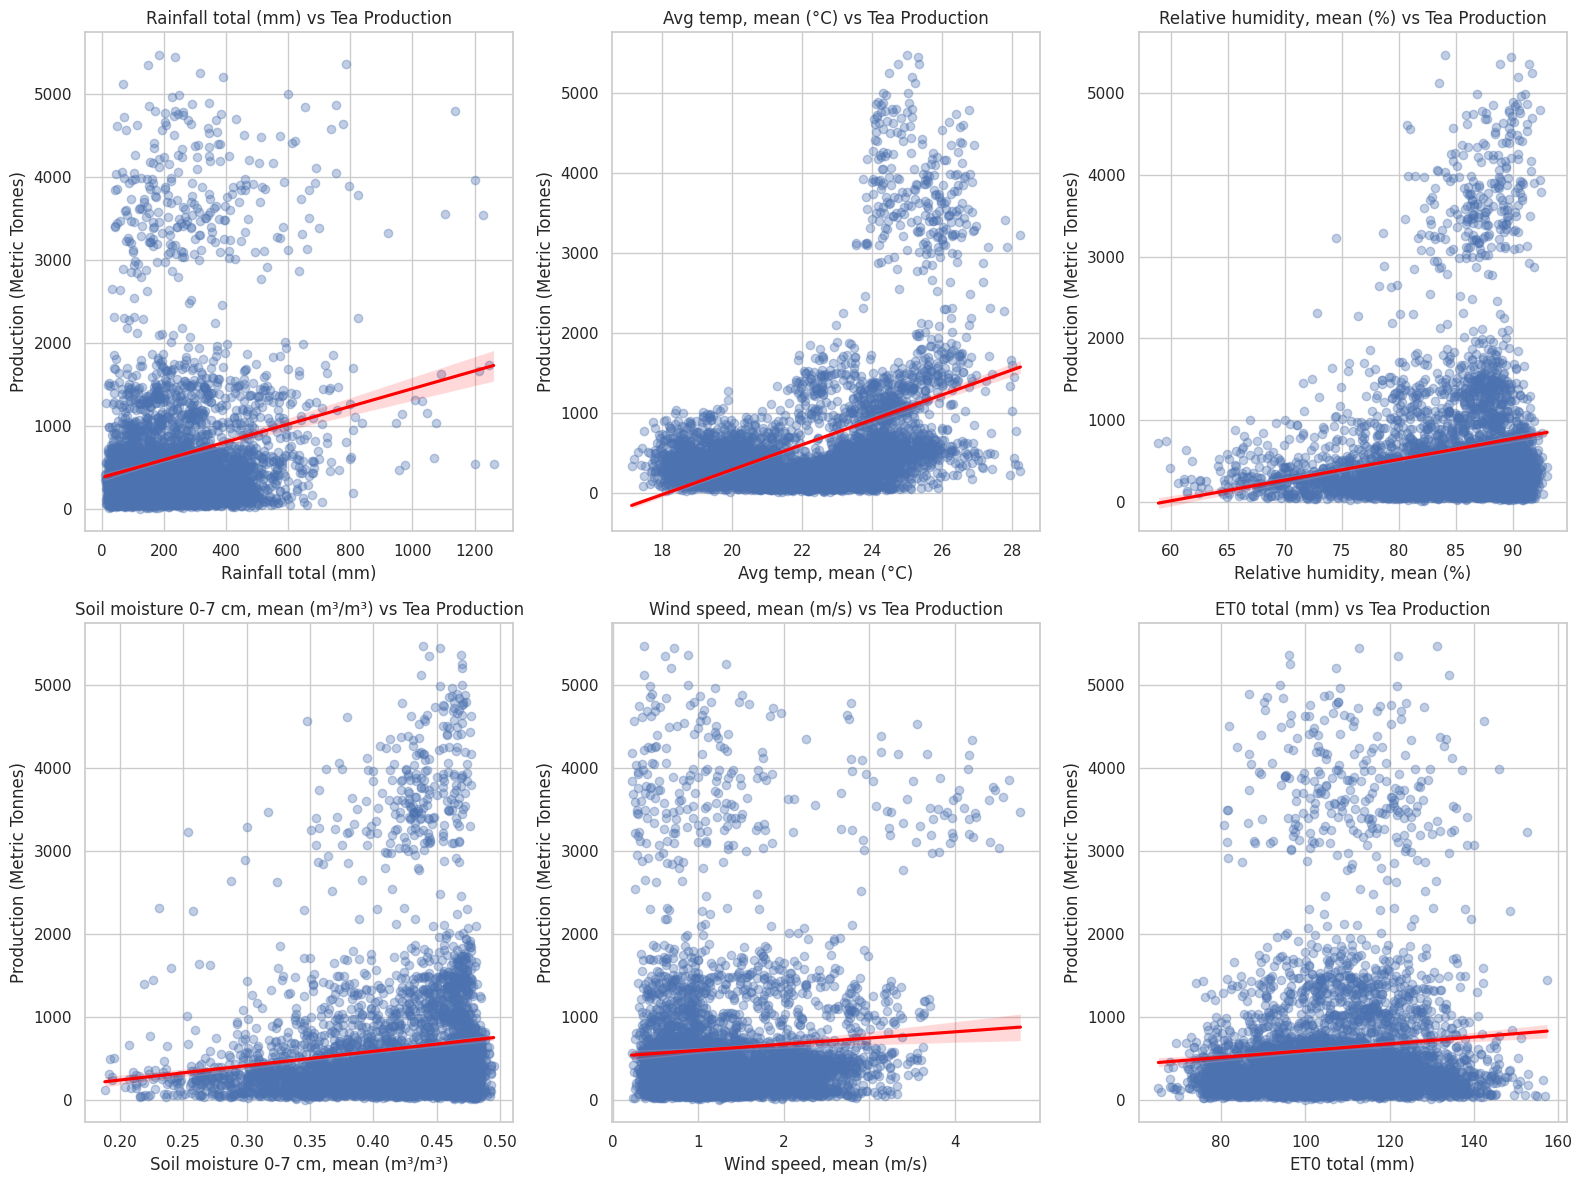

In [ ]:
weather_variables = [
    'Rainfall total (mm)',
    'Avg temp, mean (°C)',
    'Relative humidity, mean (%)',
    'Soil moisture 0-7 cm, mean (m³/m³)',
    'Wind speed, mean (m/s)',
    'ET0 total (mm)'
]

plt.figure(figsize=(16, 12))

for i, col in enumerate(weather_variables, 1):

    plt.subplot(2, 3, i)

    sns.regplot(
        data=combined_df,
        x=col,
        y='production (t)',
        scatter_kws={'alpha': 0.35},
        line_kws={'color': 'red'}
    )

    plt.title(f'{col} vs Tea Production')
    plt.xlabel(col)
    plt.ylabel('Production (Metric Tonnes)')

plt.tight_layout()
plt.show()

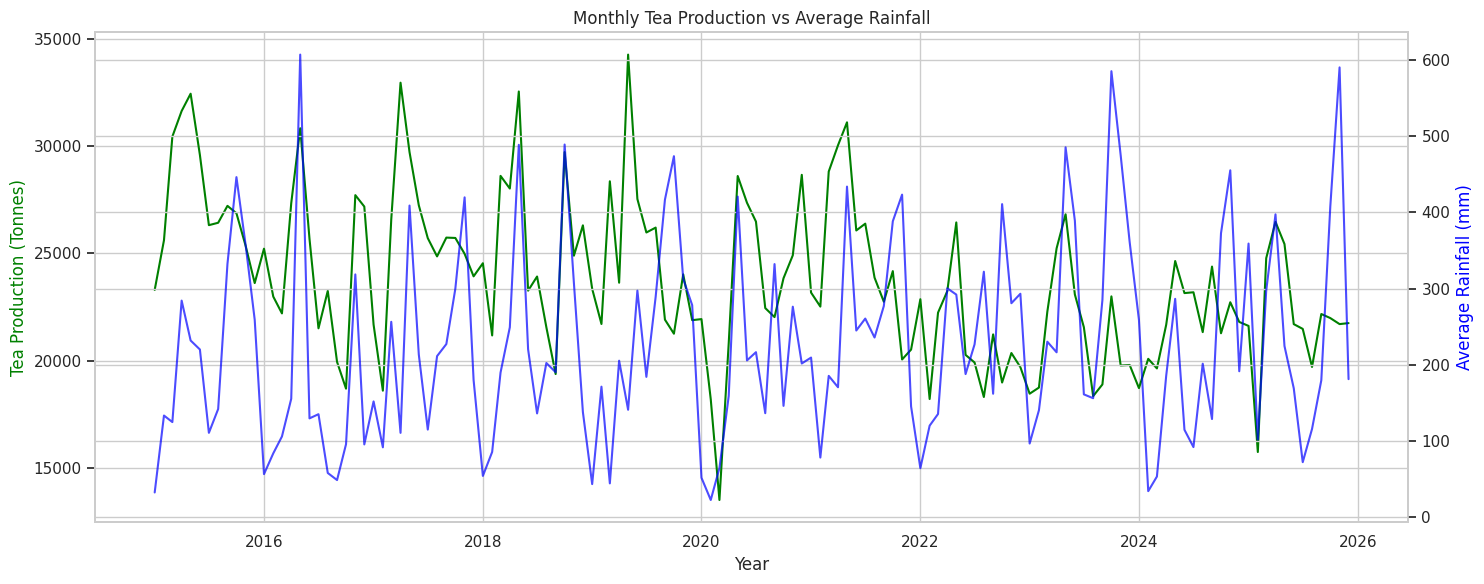

In [ ]:
# Aggregate monthly data across districts

monthly_combined = (
    combined_df.groupby('month_start')
    .agg({
        'production (t)': 'sum',
        'Rainfall total (mm)': 'mean'
    })
    .reset_index()
)

fig, ax1 = plt.subplots(figsize=(15, 6))

ax1.plot(
    monthly_combined['month_start'],
    monthly_combined['production (t)'],
    color='green',
    label='Tea Production'
)

ax1.set_xlabel('Year')
ax1.set_ylabel('Tea Production (Tonnes)', color='green')

ax2 = ax1.twinx()

ax2.plot(
    monthly_combined['month_start'],
    monthly_combined['Rainfall total (mm)'],
    color='blue',
    alpha=0.7,
    label='Average Rainfall'
)

ax2.set_ylabel('Average Rainfall (mm)', color='blue')

plt.title('Monthly Tea Production vs Average Rainfall')

plt.tight_layout()
plt.show()

In [ ]:
# Calculate district-wise correlations

district_correlations = (
    combined_df.groupby('district')
    .apply(
        lambda x: x[
            [
                'production (t)',
                'Rainfall total (mm)',
                'Avg temp, mean (°C)',
                'Relative humidity, mean (%)',
                'Soil moisture 0-7 cm, mean (m³/m³)'
            ]
        ].corr()['production (t)'].drop('production (t)')
    )
)

display(district_correlations.round(3))

/tmp/ipykernel_3112/428113982.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


production (t),Rainfall total (mm),"Avg temp, mean (°C)","Relative humidity, mean (%)","Soil moisture 0-7 cm, mean (m³/m³)"
district,,,,
Agarapathana,0.177,0.150,0.152,0.159
Balangoda,0.196,0.120,0.163,0.254
Balangoda/Rakwana,0.293,0.247,0.246,0.319
Bandarawela/Poonagalla,0.139,0.285,0.025,0.097
Bogawantalawa,0.232,0.175,0.099,0.105
Demodara/Haliella/Badulla,-0.002,0.343,-0.006,0.015
Deniyaya,0.166,-0.058,0.376,0.402
Ella / Namunukula,-0.016,0.233,-0.000,-0.002
Galle,0.193,-0.115,0.475,0.492


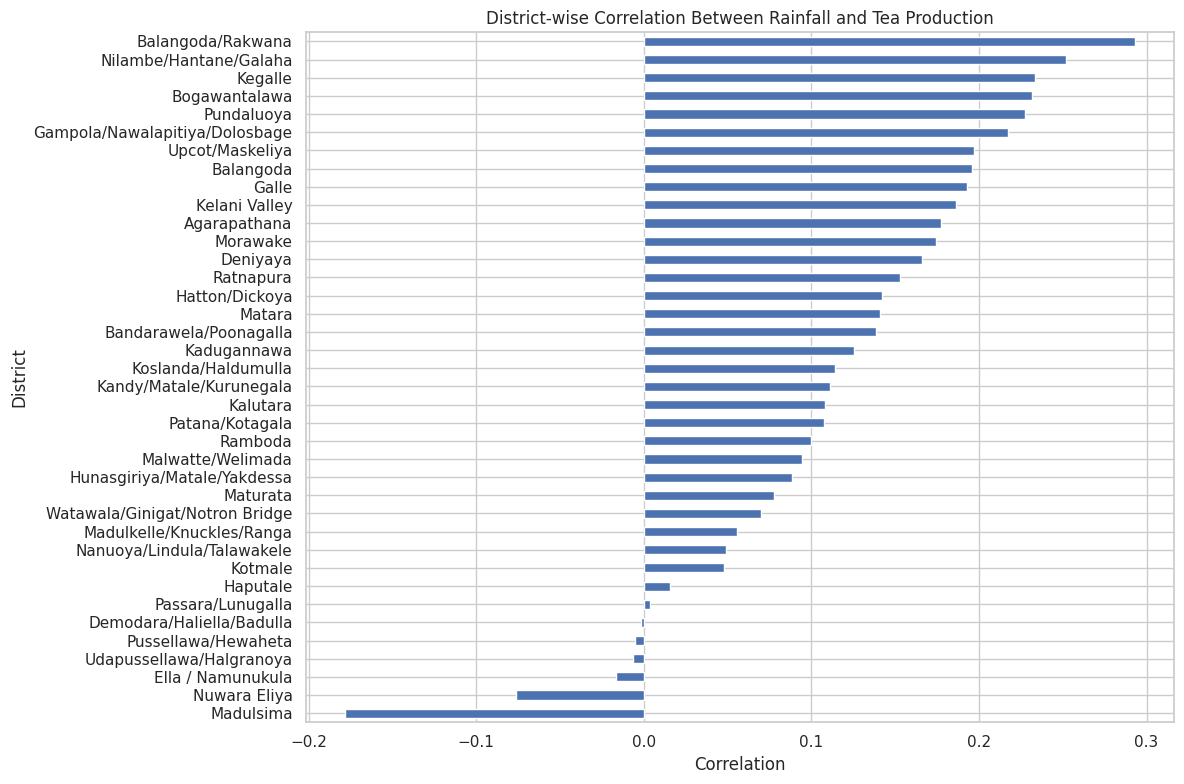

In [ ]:
rainfall_corr = (
    district_correlations['Rainfall total (mm)']
    .sort_values()
)

plt.figure(figsize=(12, 8))

rainfall_corr.plot(kind='barh')

plt.title('District-wise Correlation Between Rainfall and Tea Production')
plt.xlabel('Correlation')
plt.ylabel('District')

plt.tight_layout()
plt.show()

,production (t),Rainfall total (mm)_lag1,"Avg temp, mean (°C)_lag1","Relative humidity, mean (%)_lag1"
production (t),1.000,0.178,0.433,0.158
Rainfall total (mm)_lag1,0.178,1.000,0.083,0.593
"Avg temp, mean (°C)_lag1",0.433,0.083,1.000,-0.240
"Relative humidity, mean (%)_lag1",0.158,0.593,-0.240,1.000


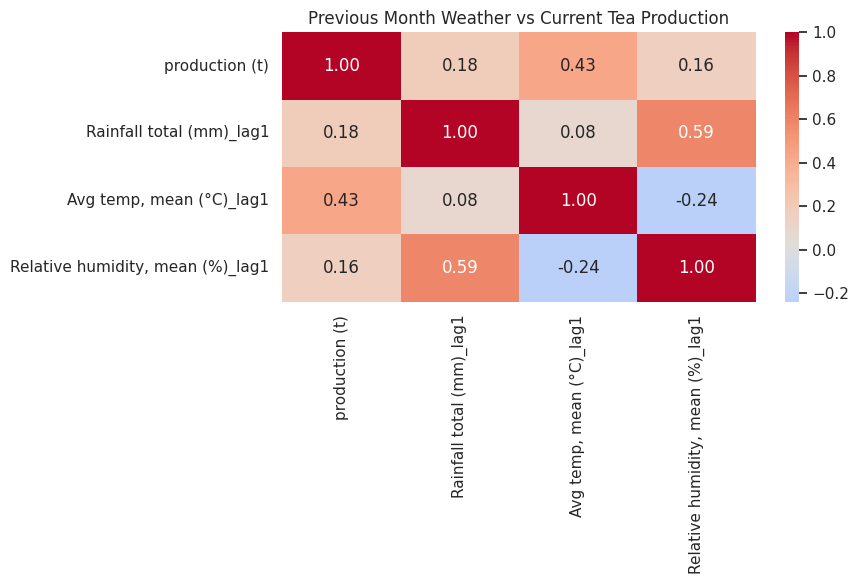

In [ ]:
# Sort records by district and month

combined_df = combined_df.sort_values(
    ['district', 'month_start']
).copy()

# Create previous-month weather variables

lag_variables = [
    'Rainfall total (mm)',
    'Avg temp, mean (°C)',
    'Relative humidity, mean (%)'
]

for col in lag_variables:

    combined_df[f'{col}_lag1'] = (
        combined_df.groupby('district')[col].shift(1)
    )

# Calculate lagged correlations

lag_corr = combined_df[
    [
        'production (t)',
        'Rainfall total (mm)_lag1',
        'Avg temp, mean (°C)_lag1',
        'Relative humidity, mean (%)_lag1'
    ]
].corr()

display(lag_corr.round(3))

plt.figure(figsize=(9, 6))

sns.heatmap(
    lag_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Previous Month Weather vs Current Tea Production')

plt.tight_layout()
plt.show()

## Final data set preparation

In [ ]:
# Create a copy of the cleaned tea production dataset
tea_final = district_clean.copy()

# Standardise the date column to monthly format
tea_final['month_start'] = (
    pd.to_datetime(tea_final['month_start'])
    .dt.to_period('M')
    .dt.to_timestamp()
)

# Remove unnecessary spaces from regional group names
tea_final['regional group'] = (
    tea_final['regional group']
    .astype(str)
    .str.strip()
)

# Display the prepared tea dataset
display(tea_final.head())

print("Tea dataset shape:", tea_final.shape)

,month_start,year,month,district,regional group,production (kg),production (t),unit_difference,2017_discrepancy_period
0,2015-01-01,2015,1,Nuwara Eliya,Nuwara Eliya,240949.5,240.9495,0.0,False
1,2015-01-01,2015,1,Agarapathana,Westerns,723975.0,723.9750,0.0,False
2,2015-01-01,2015,1,Bogawantalawa,Westerns,458924.0,458.9240,0.0,False
3,2015-01-01,2015,1,Hatton/Dickoya,Westerns,603749.0,603.7490,0.0,False
4,2015-01-01,2015,1,Nanuoya/Lindula/Talawakele,Westerns,681714.5,681.7145,0.0,False


Tea dataset shape: (5016, 9)


In [ ]:
# Create a copy of the cleaned weather dataset
weather_final = weather_eda.copy()

# Standardise the date column
weather_final['Month'] = (
    pd.to_datetime(weather_final['Month'])
    .dt.to_period('M')
    .dt.to_timestamp()
)

# Clean regional group names
weather_final['Region (tea regional group)'] = (
    weather_final['Region (tea regional group)']
    .astype(str)
    .str.strip()
)

# Select the weather variables to include
weather_features = [
    'Rainfall total (mm)',
    'Max temp, mean (°C)',
    'Min temp, mean (°C)',
    'Avg temp, mean (°C)',
    'Relative humidity, mean (%)',
    'Solar radiation, mean (MJ/m²/day)',
    'Wind speed, mean (m/s)',
    'ET0 total (mm)',
    'Sunshine, mean (h/day)',
    'Soil moisture 0-7 cm, mean (m³/m³)'
]

# Aggregate weather data by month and regional group
weather_monthly = (
    weather_final
    .groupby(
        ['Month', 'Region (tea regional group)'],
        as_index=False
    )[weather_features]
    .mean()
)

# Display the aggregated weather dataset
display(weather_monthly.head())

print("Aggregated weather dataset shape:", weather_monthly.shape)

,Month,Region (tea regional group),Rainfall total (mm),"Max temp, mean (°C)","Min temp, mean (°C)","Avg temp, mean (°C)","Relative humidity, mean (%)","Solar radiation, mean (MJ/m²/day)","Wind speed, mean (m/s)",ET0 total (mm),"Sunshine, mean (h/day)","Soil moisture 0-7 cm, mean (m³/m³)"
0,2015-01-01,Low Grown,53.114889,28.166444,20.715889,24.332000,81.5490,19.445778,0.607556,113.457222,7.692111,0.391778
1,2015-01-01,Mediums,27.370500,25.399200,18.129900,21.623900,81.0883,18.327400,1.042200,103.750800,6.993900,0.372900
2,2015-01-01,Nuwara Eliya,23.450000,21.942000,15.393000,18.280000,80.3180,17.987000,0.982000,97.112000,6.734000,0.373000
3,2015-01-01,Uda Pussellawa,27.972000,22.135000,15.557500,18.457500,80.4215,17.979500,0.986000,97.109500,6.729500,0.376000
4,2015-01-01,Uvas,24.643875,24.259875,17.160125,20.442375,81.7510,17.928875,1.263500,100.616375,6.681750,0.355750


Aggregated weather dataset shape: (846, 12)


In [ ]:
# Get unique regional groups from both datasets
tea_regions = set(tea_final['regional group'].dropna().unique())

weather_regions = set(
    weather_monthly['Region (tea regional group)'].dropna().unique()
)

print("Tea regional groups:")
print(sorted(tea_regions))

print("\nWeather regional groups:")
print(sorted(weather_regions))

print("\nRegions present in tea data but missing in weather data:")
print(tea_regions - weather_regions)

print("\nRegions present in weather data but missing in tea data:")
print(weather_regions - tea_regions)

Tea regional groups:
['Low Grown', 'Mediums', 'Nuwara Eliya', 'Uda Pussellawa', 'Uvas', 'Westerns']

Weather regional groups:
['Low Grown', 'Mediums', 'Nuwara Eliya', 'Uda Pussellawa', 'Uvas', 'Westerns']

Regions present in tea data but missing in weather data:
set()

Regions present in weather data but missing in tea data:
set()


In [ ]:
# Check duplicate month + district combinations in tea data
tea_duplicates = tea_final.duplicated(
    subset=['month_start', 'district']
).sum()

# Check duplicate month + regional group combinations in weather data
weather_duplicates = weather_monthly.duplicated(
    subset=['Month', 'Region (tea regional group)']
).sum()

print("Duplicate tea month-district keys:", tea_duplicates)
print("Duplicate weather month-region keys:", weather_duplicates)

Duplicate tea month-district keys: 0
Duplicate weather month-region keys: 0


In [ ]:
# Merge using month and regional group
merged_df = pd.merge(
    tea_final,
    weather_monthly,
    left_on=['month_start', 'regional group'],
    right_on=['Month', 'Region (tea regional group)'],
    how='left',
    validate='many_to_one',
    indicator=True
)

# Remove the duplicate date and region columns from the weather side
merged_df.drop(
    columns=['Month', 'Region (tea regional group)', '_merge'],
    inplace=True
)

# Display the merged dataset
display(merged_df.head())

print("Merged dataset shape:", merged_df.shape)

,month_start,year,month,district,regional group,production (kg),production (t),unit_difference,2017_discrepancy_period,Rainfall total (mm),"Max temp, mean (°C)","Min temp, mean (°C)","Avg temp, mean (°C)","Relative humidity, mean (%)","Solar radiation, mean (MJ/m²/day)","Wind speed, mean (m/s)",ET0 total (mm),"Sunshine, mean (h/day)","Soil moisture 0-7 cm, mean (m³/m³)"
0,2015-01-01,2015,1,Nuwara Eliya,Nuwara Eliya,240949.5,240.9495,0.0,False,23.450000,21.942000,15.393000,18.28000,80.31800,17.987000,0.982000,97.112000,6.734000,0.3730
1,2015-01-01,2015,1,Agarapathana,Westerns,723975.0,723.9750,0.0,False,24.373125,22.531625,15.719375,18.78025,80.21175,18.319875,0.684125,97.930125,6.955125,0.4035
2,2015-01-01,2015,1,Bogawantalawa,Westerns,458924.0,458.9240,0.0,False,24.373125,22.531625,15.719375,18.78025,80.21175,18.319875,0.684125,97.930125,6.955125,0.4035
3,2015-01-01,2015,1,Hatton/Dickoya,Westerns,603749.0,603.7490,0.0,False,24.373125,22.531625,15.719375,18.78025,80.21175,18.319875,0.684125,97.930125,6.955125,0.4035
4,2015-01-01,2015,1,Nanuoya/Lindula/Talawakele,Westerns,681714.5,681.7145,0.0,False,24.373125,22.531625,15.719375,18.78025,80.21175,18.319875,0.684125,97.930125,6.955125,0.4035


Merged dataset shape: (5016, 19)


In [ ]:
print("Number of rows:", merged_df.shape[0])
print("Number of columns:", merged_df.shape[1])

print("\nColumn names:")
print(merged_df.columns.tolist())

print("\nData types:")
print(merged_df.dtypes)

Number of rows: 5016
Number of columns: 19

Column names:
['month_start', 'year', 'month', 'district', 'regional group', 'production (kg)', 'production (t)', 'unit_difference', '2017_discrepancy_period', 'Rainfall total (mm)', 'Max temp, mean (°C)', 'Min temp, mean (°C)', 'Avg temp, mean (°C)', 'Relative humidity, mean (%)', 'Solar radiation, mean (MJ/m²/day)', 'Wind speed, mean (m/s)', 'ET0 total (mm)', 'Sunshine, mean (h/day)', 'Soil moisture 0-7 cm, mean (m³/m³)']

Data types:
month_start                           datetime64[ns]
year                                           int64
month                                          int64
district                                      object
regional group                                object
production (kg)                              float64
production (t)                               float64
unit_difference                              float64
2017_discrepancy_period                         bool
Rainfall total (mm)                   

In [ ]:
# Missing value count and percentage
final_missing_report = pd.DataFrame({
    'Missing Count': merged_df.isnull().sum(),
    'Missing Percentage': (
        merged_df.isnull().sum() / len(merged_df)
    ) * 100
})

display(
    final_missing_report.sort_values(
        'Missing Percentage',
        ascending=False
    )
)

,Missing Count,Missing Percentage
month_start,0,0.0
year,0,0.0
month,0,0.0
district,0,0.0
regional group,0,0.0
production (kg),0,0.0
production (t),0,0.0
unit_difference,0,0.0
2017_discrepancy_period,0,0.0
Rainfall total (mm),0,0.0


In [ ]:
# Check duplicate records
print(
    "Total duplicate rows:",
    merged_df.duplicated().sum()
)

# Check duplicate month-district combinations
print(
    "Duplicate month-district keys:",
    merged_df.duplicated(
        subset=['month_start', 'district']
    ).sum()
)

Total duplicate rows: 0
Duplicate month-district keys: 0


In [ ]:
print("Start date:", merged_df['month_start'].min())
print("End date:", merged_df['month_start'].max())

print(
    "Number of unique months:",
    merged_df['month_start'].nunique()
)

print(
    "Number of districts:",
    merged_df['district'].nunique()
)

Start date: 2015-01-01 00:00:00
End date: 2025-12-01 00:00:00
Number of unique months: 132
Number of districts: 38


In [ ]:
print("Original tea records:", len(tea_final))
print("Final merged records:", len(merged_df))

if len(tea_final) == len(merged_df):
    print("Record count validation: PASSED")
else:
    print("Record count validation: CHECK REQUIRED")

Original tea records: 5016
Final merged records: 5016
Record count validation: PASSED


In [ ]:
# Sort records by district and month
merged_df = merged_df.sort_values(
    by=['district', 'month_start']
).reset_index(drop=True)

# Export the final dataset
merged_df.to_csv(
    'final_tea_weather_merged_dataset.csv',
    index=False
)

print("Final merged dataset exported successfully!")

Final merged dataset exported successfully!


In [ ]:
from google.colab import files

files.download('final_tea_weather_merged_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>